# Sensitivity of the E3SM MCS climatology to `heavy_rainrate_thresh`

The MCSMIP definition of a robust MCS needs the maximum precipitation-feature rain rate to exceed `heavy_rainrate_thresh` (10 mm/h)
for at least 4 hours. At the coarse resolution of E3SM (25 and 100 km) rain rates rarely reach 10 mm/h, so there are far fewer MCSs
than observed. This notebook compares the MCS climatology of one year of E3SM (2010) tracked with lower thresholds against the
observation. The key metric is the **MCS precipitation fraction** (MCS precipitation / total precipitation); the MCS cloud frequency and
the MCS precipitation are shown as complementary figures.

**How the runs were made** (`tracking_e3sm/gen_heavyrain_sensitivity.py`): each run is the production run of the year with one
`heavy_rainrate_thresh`, repeated from the matchpf step (which reads the key for the heavy-rain sums) through robustmcs, mapfeature,
speed and rainmap, with the earlier steps shared with the production run. Each run has its 12 monthly rain maps and their climatology
(`mcs_rainmap_monthly_climo_YYYY01_YYYY12.nc`). The baseline is the production run (10 mm/h).

**Figures** (per model and variable): the observation (a), the model - OBS bias of every threshold, and the zonal mean of all runs in
the last panel. **Table**: number of robust MCSs, heavy-rain total and area means of the three variables for every threshold.

**How to use:** change only the *Configuration* cell.

In [1]:
import copy
import os
import warnings

import numpy as np
import pandas as pd
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cf
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.colors as colors
import colormaps as cmaps

# Fonts: the same in all figures of the notebook (and in the other notebooks of this SCREAM / E3SM evaluation)
mpl.rcParams['font.family'] = 'STIXGeneral'
mpl.rcParams['mathtext.fontset'] = 'stix'

## Configuration

In [2]:
# ====================================================================================================================================
# CONFIGURATION (the only cell to edit)
# ====================================================================================================================================

# ---- Output ----------------------------------------------------------------------------------------------------------------------
figdir = '/pscratch/sd/f/feng045/SCREAM-decadal/figures_e3sm/heavyrain_sensitivity/'   # folder of figures and the summary table
dpi = 200

# ---- Colors of the sources: the one place to change them (every line, contour and bar of a source takes its color from here) ----------------------------
# The simulations come in pairs, one color family per pair; the darker color is the better run, the lighter one the other run:
#   3-km SCREAM red (CTL tomato, TUNE firebrick), 13-km SCREAM blue (CTL deepskyblue, TUNE royalblue), E3SM green (100-km limegreen, 25-km forestgreen)
COLORS = {'obs': 'black', 'ne120': 'forestgreen', 'ne30': 'limegreen'}      # OBS, E3SM 25 km (ne120) and 100 km (ne30)

# ---- Observation (reference): the climatology file and the valid-data mask ------------------------------------------------------------
CFS = '/global/cfs/cdirs/m1867/zfeng/SCREAM-decadal'
OBS = dict(label='OBS', climo=f'{CFS}/mcs_global_v3/MCSMIP/monthly/mcs_rainmap_monthly_climo_200701_201712.nc',
           period='2007-2017', color=COLORS['obs'], linewidth=3.0, linestyle='-')
maskfile = f'{CFS}/maps/merg_valid_fraction_1998_2024.nc'
mask_var = 'fraction_30min_all'
valid_frac_min = 0.75
mask_to_obs_valid = True
topofile = f'{CFS}/maps/era5_orography.nc'
terrain_levels = [1000]           # [m] terrain contour(s); None = off

# ---- The experiment --------------------------------------------------------------------------------------------------------------
YEAR = 2010                       # year of the runs
BASELINE_THRESHOLD = 10.0         # [mm/h] the production value (the production run is the baseline)
THRESHOLDS = [5.0, 3.0, 2.0, 1.5, 1.0]   # [mm/h] tested values, in plotting order
SHOW_BASELINE_MAP = False         # True: also draw the bias map of the baseline (it is always a line in the zonal-mean panel)
E3SM = '/global/cfs/cdirs/m1867/zfeng/E3SM_polun'                 # CFS copy (identical to the pscratch tree, checked 2026-11-18)
# root: the folder with the production years and the sensitivity runs (<root>/<year>, <root>_sens/heavyrain_<tag>/<year>)
MODELS = {
    'ne120': dict(label='E3SM 25 km', root=f'{E3SM}/ne120_remap_0.1deg/mcs_tbpf', color=COLORS['ne120']),
    'ne30': dict(label='E3SM 100 km', root=f'{E3SM}/ne30_remap_0.1deg/mcs_tbpf', color=COLORS['ne30']),
}
# Line styles of the zonal-mean panel: the baseline, and one color per threshold taken from this colormap (light to dark as the value falls)
baseline_style = dict(color='gray', linewidth=1.8, linestyle='--')
threshold_cmap = 'plasma'

# ---- Seasons, variables and maps ---------------------------------------------------------------------------------------------------
SEASONS = ['ANN']                 # any of 'ANN', 'DJF', 'MAM', 'JJA', 'SON'
VARIABLES = {
    'pcpfrac': dict(title='MCS precipitation fraction', num='mcs_precipitation', den='precipitation', scale=100.0,
                    cmap=('WhiteBlueGreenYellowRed', 0.0, 0.8), levels=list(range(0, 81, 10)), obs_over='firebrick', obs_under='white',
                    bias_cmap='BrBG', bias_levels=[-50, -40, -30, -20, -10, -5, 5, 10, 20, 30, 40, 50],
                    cblabel='MCS precipitation fraction (%)', short_cblabel='Fraction (%)', bias_cblabel='Model - OBS (%)',
                    zonal_ylabel='Fraction (%)'),
    'cloudfreq': dict(title='MCS cloud frequency', num='mcs_cloud_freq', den=None, scale=1.0,
                      cmap='cet_l_wcmr', levels=[0.5, 1, 2, 3, 4, 6, 8, 10, 13, 16, 20], obs_over='firebrick', obs_under='white',
                      bias_cmap='BrBG', bias_levels=[-10, -8, -6, -4, -2, -1, 1, 2, 4, 6, 8, 10],
                      cblabel='MCS cloud frequency (%)', short_cblabel='Frequency (%)', bias_cblabel='Model - OBS (%)',
                      zonal_ylabel='Frequency (%)'),
    'mcspcp': dict(title='MCS precipitation', num='mcs_precipitation', den=None, scale=1.0,
                   cmap='WhBlGrYeRe', levels=[0.1, 0.2, 0.5, 1, 1.5, 2, 3, 4, 6, 8, 10], obs_over='firebrick', obs_under='white',
                   bias_cmap='BrBG', bias_levels=[-4, -3, -2, -1.5, -1, -0.5, 0.5, 1, 1.5, 2, 3, 4],
                   cblabel='MCS precipitation (mm day$^{-1}$)', short_cblabel='mm day$^{-1}$', bias_cblabel='Model - OBS (mm day$^{-1}$)',
                   zonal_ylabel='mm day$^{-1}$'),
}
VARIABLES_TO_PLOT = ['pcpfrac', 'cloudfreq', 'mcspcp']      # key metric first
central_lon = 225
lat_cut = (-60.0, 60.0)
lat_range = (-59.9, 59.9)
lat_lines = None
ncol = 2
figwidth = 15
figsize = None                    # (width, height) [inch]; None = the width above and the height solved so that the maps have their true shape
panel_aspect = None               # height / width of a map cell in the solved height; None = true aspect of the projection
aspect = 'auto'                   # 'auto': maps fill their cell; 'equal': cartopy keeps the true shape inside any cell
font_scale = 1.3                  # factor on the font sizes of the figures (the fonts are STIXGeneral, set in the imports cell)
fontsize = 12 * font_scale
cb_fontsize = 11 * font_scale
max_coord_diff = 0.01
plot_coarsen = 1                  # 1 = every 0.1 degree cell; 2 = four times faster
zonal_bin_deg = 2.0
zonal_legend_ncol = 1
zonal_legend_outside = True         # the legend is to the right of the bias colorbar (may reach beyond the figure); False: inside the axes
zonal_headroom = 0.1
show_period_in_legend = False
# Interannual spread of the OBS zonal mean (the shaded band: 25th-75th percentile across the years of the annual zonal mean of each year)
show_obs_iqr = True
obs_monthly_dir = '/global/cfs/cdirs/wcm_shr/gsharing/MCS_Global/V3/MCSMIP/stats_mcsmip/monthly'   # mcs_rainmap_YYYYMM.nc of the OBS (original files of the V3 dataset on CFS)
obs_iqr_years = (2007, 2017)
obs_iqr_method = 'cell_iqr'       # 'cell_iqr' (zonal mean of the local interannual IQR) or 'zonal_iqr' (IQR of the annual zonal mean)
obs_iqr_cache = '/pscratch/sd/f/feng045/SCREAM-decadal/mcs_global_v3/obs_zonal_annual_2007_2017.nc'   # shared with the maps notebook
obs_iqr_color = 'gray'
obs_iqr_alpha = 0.35

## Functions
(The same functions as in `plot_global_mcs_climo_rainmap_scream_e3sm_obs.ipynb`.)

In [3]:
# Land outline of the maps (Natural Earth 110 m, cached by Cartopy)
LAND = cf.NaturalEarthFeature('physical', 'land', '110m')
# Months of each season of the 12-month climatologies
SEASON_MONTHS = {'ANN': list(range(1, 13)), 'DJF': [12, 1, 2], 'MAM': [3, 4, 5], 'JJA': [6, 7, 8], 'SON': [9, 10, 11]}


def truncate_colormap(cmap, minval=0.0, maxval=1.0, n=256):
    """
    Use only part of a colormap.

    Args:
        cmap: matplotlib colormap
            Colormap to cut.
        minval, maxval: float (default: 0.0, 1.0)
            Start and end of the part to keep, as fractions of the colormap.
        n: int (default: 256)
            Number of colors of the new colormap.

    Returns:
        cmap: LinearSegmentedColormap
    """
    return mpl.colors.LinearSegmentedColormap.from_list(
        f'trunc({cmap.name},{minval:.2f},{maxval:.2f})', cmap(np.linspace(minval, maxval, n)))


def get_cmap(spec, over=None, under=None):
    """
    Colormap of a Configuration entry.

    Args:
        spec: str or tuple
            Name of a colormaps-package or matplotlib colormap, or (name, minval, maxval) to use only that part of it.
        over, under: color (default: None)
            Colors of values above / below the color levels; None keeps the end colors of the colormap.

    Returns:
        cmap: matplotlib colormap (a copy)
    """
    # A tuple selects part of the colormap
    name, minval, maxval = spec if isinstance(spec, tuple) else (spec, 0.0, 1.0)
    # The colormaps package first, then matplotlib
    cmap = getattr(cmaps, name) if hasattr(cmaps, name) else mpl.colormaps[name]
    if (minval, maxval) != (0.0, 1.0):
        cmap = truncate_colormap(cmap, minval, maxval)
    # A copy, so that set_over / set_under do not change the shared colormap
    cmap = copy.copy(cmap)
    if over is not None:
        cmap.set_over(over)
    if under is not None:
        cmap.set_under(under)
    return cmap


def load_climo(path, obs_lat=None, obs_lon=None, lat_cut=(-60.0, 60.0), max_coord_diff=0.01):
    """
    Open a monthly climatology file, cut it to a latitude band and give it the coordinates of the OBS grid.

    Args:
        path: str
            Climatology file (12 months).
        obs_lat, obs_lon: DataArray (default: None)
            Latitude and longitude of the OBS grid. None for the OBS file itself, whose coordinates define the grid.
        lat_cut: tuple (default: (-60, 60))
            Latitude band to keep.
        max_coord_diff: float (default: 0.01)
            [deg] The source grid must have the same size as the OBS grid and coordinates within this difference, otherwise an
            error is raised (so a grid that is really different is never relabelled silently).

    Returns:
        ds: xarray.Dataset
            Climatology on the OBS grid.
    """
    ds = xr.open_dataset(path).sel(lat=slice(*lat_cut))
    # The OBS file itself defines the grid
    if obs_lat is None:
        return ds
    # Same size and same coordinates (within max_coord_diff) as the OBS grid, otherwise stop
    if ds.sizes['lat'] != obs_lat.size or ds.sizes['lon'] != obs_lon.size:
        raise ValueError(f'{path}: grid {ds.sizes["lat"]} x {ds.sizes["lon"]} differs from the OBS grid {obs_lat.size} x {obs_lon.size}')
    dlat = float(np.abs(ds['lat'].values - obs_lat.values).max())
    dlon = float(np.abs(ds['lon'].values - obs_lon.values).max())
    if dlat > max_coord_diff or dlon > max_coord_diff:
        raise ValueError(f'{path}: coordinates differ from the OBS grid by {dlat:.4f} deg (lat), {dlon:.4f} deg (lon)')
    return ds.assign_coords(lat=obs_lat.values, lon=obs_lon.values)


def season_mean(da, season):
    """
    Mean over the months of a season of a 12-month climatology (every month has the same weight).

    Args:
        da: DataArray [time, lat, lon]
            Monthly climatology with a datetime `time` coordinate.
        season: str
            'ANN', 'DJF', 'MAM', 'JJA' or 'SON'.

    Returns:
        mean: DataArray [lat, lon] (loaded into memory)
    """
    months = SEASON_MONTHS[season]
    return da.isel(time=np.isin(da['time.month'].values, months)).mean('time').load()


def compute_fields(datasets, variables, season):
    """
    Season mean fields of every variable and source.

    Args:
        datasets: dict
            source key -> climatology Dataset (on the OBS grid).
        variables: dict
            The VARIABLES entries (num, den, scale).
        season: str
            'ANN', 'DJF', 'MAM', 'JJA' or 'SON'.

    Returns:
        fields: dict
            fields[variable][source] = dict(num=DataArray, den=DataArray or None, map=DataArray), where map is the displayed field
            (scale * num, or scale * num / den where den > 0).
    """
    fields = {}
    # Loop over the variables
    for vkey, spec in variables.items():
        fields[vkey] = {}
        # Loop over the sources: the season means of the numerator (and denominator), then the displayed field
        for skey, ds in datasets.items():
            num = season_mean(ds[spec['num']], season)
            den = season_mean(ds[spec['den']], season) if spec['den'] else None
            field = spec['scale'] * num if den is None else (spec['scale'] * num / den).where(den > 0)
            fields[vkey][skey] = dict(num=num, den=den, map=field)
    return fields


def zonal_mean_cosw(num, den=None, scale=1.0, valid=None, bin_deg=2.0, lat_cut=(-60.0, 60.0)):
    """
    Zonal mean in latitude bins, cos(latitude)-weighted over the used cells.

    All cells of one latitude row have the same area, so a mean along a row needs no weight; the weights matter when rows are
    combined into a bin. With a denominator the result is the ratio of the weighted sums (not the mean of cell ratios).

    Args:
        num: DataArray [lat, lon]
            Field (or numerator).
        den: DataArray [lat, lon] (default: None)
            Denominator; None for a plain zonal mean.
        scale: float (default: 1.0)
            Factor of the result (100 for a percentage).
        valid: ndarray of bool [lat, lon] (default: None)
            Cells to use; None = all finite cells. Cells where num or den is NaN are never used.
        bin_deg: float (default: 2.0)
            [deg] Width of the latitude bins.
        lat_cut: tuple (default: (-60, 60))
            Latitude band of the bins.

    Returns:
        centers: ndarray [nbins]
            Bin centers (deg).
        values: ndarray [nbins]
            Zonal mean (NaN where a bin has no valid cell).
    """
    lat = num['lat'].values
    nvals = num.values.astype(float)
    # Cells used: finite numerator (and denominator) and valid in the mask
    use = np.isfinite(nvals)
    if den is not None:
        dvals = den.values.astype(float)
        use &= np.isfinite(dvals)
    if valid is not None:
        use &= valid
    # Sums along each latitude row, and the weight (cos latitude) of each row
    weight = np.cos(np.deg2rad(lat))
    row_num = np.where(use, nvals, 0.0).sum(axis=1)
    row_cnt = use.sum(axis=1)
    row_den = np.where(use, dvals, 0.0).sum(axis=1) if den is not None else None
    # Latitude bins and the bin of every row
    edges = np.arange(lat_cut[0], lat_cut[1] + 0.5 * bin_deg, bin_deg)
    centers = 0.5 * (edges[:-1] + edges[1:])
    index = np.digitize(lat, edges) - 1
    values = np.full(centers.size, np.nan)
    # Loop over the latitude bins: weighted mean (or ratio of weighted sums) of the rows of the bin
    for b in range(centers.size):
        rows = index == b
        if not rows.any():
            continue
        numerator = (weight[rows] * row_num[rows]).sum()
        denominator = (weight[rows] * (row_cnt[rows] if den is None else row_den[rows])).sum()
        if denominator > 0:
            values[b] = scale * numerator / denominator
    return centers, values


def map_aspect(projection, lat_range=(-59.9, 59.9)):
    """
    True height / width of a map drawn in a projection between two latitudes (the shape the map has when it is not stretched).

    Args:
        projection: cartopy CRS
            Map projection (for example Robinson).
        lat_range: tuple (default: (-59.9, 59.9))
            [deg] Latitudes of the bottom and top edge.

    Returns:
        aspect: float
            Height of the projected map between the two latitudes divided by the full width of the projection (0.39 for Robinson, 60S-60N).
    """
    x_min, x_max = projection.x_limits
    # The projected y of the two latitudes (along the central meridian)
    y = [projection.transform_point(0.0, lat, ccrs.PlateCarree())[1] for lat in lat_range]
    return (max(y) - min(y)) / (x_max - x_min)


def percentiles_over_years(stack, qs):
    """
    Percentiles along the first axis of a [year, lat, lon] array, NaN skipped, with the linear interpolation of numpy.nanpercentile but
    vectorised (np.nanpercentile applies a Python function to every cell when there are NaNs, which takes minutes for 4 million cells).

    Args:
        stack: ndarray [n, ...]
            Values of the n years in every cell.
        qs: list of float
            Percentiles (0-100).

    Returns:
        out: list of ndarray [...]
            One field per percentile; NaN where a cell has no value in any year.
    """
    srt = np.sort(stack, axis=0)                          # NaN sorts to the end
    n = np.sum(~np.isnan(stack), axis=0)                  # valid years per cell
    out = []
    # The position of a percentile in the sorted valid values, and the interpolation between its two neighbours
    for q in qs:
        pos = (q / 100.0) * np.maximum(n - 1, 0)
        lo = np.floor(pos).astype(int)
        hi = np.minimum(lo + 1, np.maximum(n - 1, 0))
        frac = pos - lo
        v_lo = np.take_along_axis(srt, lo[None], axis=0)[0]
        v_hi = np.take_along_axis(srt, hi[None], axis=0)[0]
        out.append(np.where(n > 0, v_lo * (1 - frac) + v_hi * frac, np.nan))
    return out


def bias_title(label, obs_label='OBS'):
    """
    Panel title of a model - observation difference from the label of the source: '3-km (CTL − OBS)' for '3-km CTL', '25-km − OBS' for '25-km'.

    Args:
        label: str
            Source label, the grid spacing and optionally CTL or TUNE ('3-km CTL', '13-km TUNE', '25-km').
        obs_label: str (default: 'OBS')
            Label of the observation.

    Returns:
        title: str
    """
    words = label.split()
    # A SCREAM set: the grid spacing, then the experiment in the parentheses with the difference
    if len(words) > 1 and words[-1] in ('CTL', 'TUNE'):
        return f"{' '.join(words[:-1])} ({words[-1]} − {obs_label})"
    return f'{label} − {obs_label}'


def obs_zonal_band(variables, valid, monthly_dir, years, obs_lat, obs_lon, season='ANN', bin_deg=2.0, lat_cut=(-60.0, 60.0),
                   max_coord_diff=0.01, cache=None, method='cell_iqr'):
    """
    Interannual spread of the OBS zonal mean. For every year the annual (or seasonal) field is made exactly as the OBS field is made (12 monthly
    fields of the year, season mean with equal weights for the months; the fraction as the ratio of the means). Two bands are made from the yearly
    fields and the one of `method` is returned:

    * 'cell_iqr'  the 25th and 75th percentile across the years in every cell (the local interannual IQR), then the cos(latitude)-weighted zonal mean of
                  those two fields over the valid cells (for the fraction: the IQR of the yearly fraction field). A band of the typical local variability:
                  about 30 % of the line. The zonal mean is made like the line of the same variable: a plain area-weighted mean for a variable without
                  a denominator (cloud frequency, MCS precipitation), and for a variable with a denominator (the fraction) a PRECIPITATION-WEIGHTED
                  mean, i.e. the ratio of sums with the climatological denominator (the mean of the yearly denominators) as the weight. (Before
                  2026-11-18 the fraction percentiles were averaged with area weights only: that band was centred on the mean of the cell fractions,
                  about 6 % below the precipitation-weighted line, which is dominated by the rainy cells.)
    * 'zonal_iqr' the zonal mean of every year (the fraction as the ratio of the zonal means), then the 25th and 75th percentile across the years in every
                  latitude bin: the variability of the zonal mean itself, only 2-10 % of the line.

    Args:
        variables: dict
            The VARIABLES entries to calculate (num, den, scale).
        valid: ndarray of bool [lat, lon]
            Cells that are used (valid in OBS), or None for all finite cells.
        monthly_dir: str
            Folder of the OBS monthly rain maps mcs_rainmap_YYYYMM.nc (monthly sums: precipitation, mcs_precipitation, mcs_cloud_count and the
            number of times ntimes, as written by the tracking). They must be the same dataset as the OBS climatology file (TC included).
        years: tuple
            First and last year.
        obs_lat, obs_lon: DataArray
            Latitude and longitude of the OBS grid; a monthly file must have the same size and the same coordinates within max_coord_diff.
        season: str (default: 'ANN')
            Season of the fields.
        bin_deg: float (default: 2.0)
            [deg] Latitude bin of the zonal means.
        lat_cut: tuple (default: (-60, 60))
            Latitude band that is used.
        max_coord_diff: float (default: 0.01)
            [deg] Largest allowed difference between a monthly file grid and the OBS grid.
        cache: str (default: None)
            netCDF file with the per-year zonal means and the zonal-mean cell IQR: read when it exists and was made with the same years, season, bins,
            variables and number of valid cells, written otherwise.
        method: str (default: 'cell_iqr')
            'cell_iqr' or 'zonal_iqr' (see above).

    Returns:
        band: dict
            variable key -> dict(lat=bin centers, q25=lower bound, q75=upper bound of `method`, annual=per-year zonal means [year, bin], years=list,
            zonal_iqr=(q25, q75), cell_iqr=(q25, q75)).
    """
    if method not in ('cell_iqr', 'zonal_iqr'):
        raise ValueError(f"method must be 'cell_iqr' or 'zonal_iqr', not {method!r}")
    year_list = list(range(years[0], years[1] + 1))
    key = dict(years=f'{years[0]}-{years[1]}', season=season, bin_deg=bin_deg, variables=','.join(sorted(variables)),
               nvalid=int(valid.sum()) if valid is not None else -1, version=3)
    annual = cell_q = centers = None
    # A cache made with the same settings is read again
    if cache and os.path.exists(cache):
        with xr.open_dataset(cache) as c:
            if all(str(c.attrs.get(k)) == str(v) for k, v in key.items()):
                centers = c['lat_bin'].values
                annual = {v: c[f'annual_{v}'].values for v in variables}
                cell_q = {v: (c[f'cell_q25_{v}'].values, c[f'cell_q75_{v}'].values) for v in variables}
                print(f'OBS zonal means per year and cell IQR read from {cache}')
    # Otherwise: one pass over the years (12 monthly files each); the yearly fields are kept for the cell-wise percentiles
    if annual is None:
        annual = {v: [] for v in variables}
        cell_years = {v: [] for v in variables}
        den_years = {v: [] for v in variables}          # yearly denominator fields (variables with a denominator only): the weights of the band
        for year in year_list:
            files = [f'{monthly_dir}/mcs_rainmap_{year}{m:02d}.nc' for m in range(1, 13)]
            with xr.open_mfdataset(files, combine='nested', concat_dim='time', data_vars='minimal', compat='no_conflicts') as raw:
                raw = raw.sel(lat=slice(*lat_cut))
                if raw.sizes['lat'] != obs_lat.size or raw.sizes['lon'] != obs_lon.size or \
                        float(np.abs(raw['lat'].values - obs_lat.values).max()) > max_coord_diff:
                    raise ValueError(f'{monthly_dir}: the grid of year {year} differs from the OBS grid')
                # Monthly rates of this year, written like the climatology files (mm/day, %); cells without data in a month stay NaN
                ntimes = raw['ntimes'].where(raw['ntimes'] > 0)
                month = xr.Dataset({'precipitation': 24 * raw['precipitation'] / ntimes,
                                    'mcs_precipitation': 24 * raw['mcs_precipitation'] / ntimes,
                                    'mcs_cloud_freq': 100 * raw['mcs_cloud_count'] / ntimes}).assign_coords(lat=obs_lat.values, lon=obs_lon.values)
                fields = compute_fields({'obs': month.load()}, variables, season)
            # The zonal mean of every variable for this year, and the field itself for the cell-wise percentiles
            for v, spec in variables.items():
                f = fields[v]['obs']
                centers, values = zonal_mean_cosw(f['num'], f['den'], spec['scale'], valid, bin_deg, lat_cut)
                annual[v].append(values)
                cell_years[v].append(f['map'].values.astype(np.float32))
                if f['den'] is not None:
                    den_years[v].append(f['den'].values.astype(np.float32))
            print(f'OBS year {year}: zonal means done')
        annual = {v: np.array(a) for v, a in annual.items()}
        # Cell-wise 25th and 75th percentile across the years, then their zonal mean (same weights and cells as the OBS line)
        cell_q = {}
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', category=RuntimeWarning)
            for v in variables:
                stack = np.stack(cell_years[v])
                q25, q75 = percentiles_over_years(stack, [25, 75])
                zonal = []
                # A variable with a denominator (the fraction): the line is a ratio of sums, i.e. a mean of the cell fractions weighted by the
                # denominator, so the percentile fields are averaged with the same weight (the climatological denominator, the mean of the years)
                weight = np.nanmean(np.stack(den_years[v]), axis=0) if den_years[v] else None
                for q in (q25, q75):
                    if weight is None:
                        da = xr.DataArray(q, dims=('lat', 'lon'), coords={'lat': obs_lat.values})
                        zonal.append(zonal_mean_cosw(da, None, 1.0, valid, bin_deg, lat_cut)[1])
                    else:
                        num = xr.DataArray(np.where(np.isfinite(q), q * weight, np.nan), dims=('lat', 'lon'), coords={'lat': obs_lat.values})
                        den = xr.DataArray(weight, dims=('lat', 'lon'), coords={'lat': obs_lat.values})
                        zonal.append(zonal_mean_cosw(num, den, 1.0, valid, bin_deg, lat_cut)[1])
                cell_q[v] = (zonal[0], zonal[1])
        del cell_years, den_years
        if cache:
            out = xr.Dataset({**{f'annual_{v}': (('year', 'lat_bin'), a) for v, a in annual.items()},
                              **{f'cell_q25_{v}': (('lat_bin',), q[0]) for v, q in cell_q.items()},
                              **{f'cell_q75_{v}': (('lat_bin',), q[1]) for v, q in cell_q.items()}},
                             coords={'year': year_list, 'lat_bin': centers})
            out.attrs.update(key)
            out.to_netcdf(cache)
            print(f'OBS zonal means per year and cell IQR written to {cache}')
    # Both bands; the zonal-mean-of-years percentiles in every bin (a bin with no data in any year stays NaN)
    band = {}
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', category=RuntimeWarning)
        for v, a in annual.items():
            zonal_iqr = (np.nanpercentile(a, 25, axis=0), np.nanpercentile(a, 75, axis=0))
            chosen = cell_q[v] if method == 'cell_iqr' else zonal_iqr
            band[v] = dict(lat=centers, q25=chosen[0], q75=chosen[1], annual=a, years=year_list, zonal_iqr=zonal_iqr, cell_iqr=cell_q[v])
    return band


def coarsen_field(da, n):
    """
    Block mean of a lat-lon field over n x n cells, ignoring NaN cells (blocks that do not fill are dropped at the edges).

    Args:
        da: DataArray [lat, lon]
            Field.
        n: int
            Block size; 1 returns the field unchanged.

    Returns:
        coarse: DataArray [lat/n, lon/n]
            Block means with block-mean coordinates.
    """
    if n <= 1:
        return da
    nlat, nlon = (da.sizes['lat'] // n) * n, (da.sizes['lon'] // n) * n
    blocks = da.values[:nlat, :nlon].reshape(nlat // n, n, nlon // n, n)
    # Mean of the non-NaN cells of each block (a block of NaN stays NaN without a warning)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', category=RuntimeWarning)
        mean = np.nanmean(blocks, axis=(1, 3))
    lat = da['lat'].values[:nlat].reshape(-1, n).mean(axis=1)
    lon = da['lon'].values[:nlon].reshape(-1, n).mean(axis=1)
    return xr.DataArray(mean, coords={'lat': lat, 'lon': lon}, dims=('lat', 'lon'))


def coarsen_mask(mask, n):
    """
    Block version of a boolean [lat, lon] mask: True where any cell of the n x n block is True (blocks as in coarsen_field).

    Args:
        mask: ndarray of bool [lat, lon]
            Mask.
        n: int
            Block size; 1 returns the mask unchanged.

    Returns:
        coarse: ndarray of bool [lat/n, lon/n]
    """
    if n <= 1:
        return mask
    nlat, nlon = (mask.shape[0] // n) * n, (mask.shape[1] // n) * n
    return mask[:nlat, :nlon].reshape(nlat // n, n, nlon // n, n).any(axis=(1, 3))


def draw_map_panel(ax, data, norm, cmap, projection, data_proj, lat_range=(-59.9, 59.9), title=None, fontsize=12,
                   missing=None, terrain=None, terrain_levels=None, lat_lines=None, lon_label=False, lat_label=False,
                   row_label=None, plot_coarsen=1, missing_text=True, aspect='auto'):
    """
    Draw one lat-lon field on a Cartopy axis with the land outline, optional terrain contours, the optional missing-data
    overlay and gridlines with optional labels.

    Args:
        ax: GeoAxes
            Axis created with the `projection`.
        data: DataArray [lat, lon]
            Field to draw.
        norm, cmap: matplotlib norm and colormap
            Color mapping of the field.
        projection, data_proj: cartopy CRS
            Map projection of the axis and the CRS of the data (PlateCarree).
        lat_range: tuple (default: (-59.9, 59.9))
            Latitude range shown.
        title: str (default: None)
            Panel title (left aligned).
        fontsize: float (default: 12)
            Font size of title and gridline labels.
        missing: ndarray of bool [lat, lon] (default: None)
            Cells to cover with gray ('missing data'); None = nothing.
        terrain: DataArray (default: None)
            Terrain height with `longitude` and `latitude` coordinates; drawn as contours at `terrain_levels`.
        terrain_levels: list (default: None)
            Terrain contour levels; None = no contours.
        lat_lines: list (default: None)
            Latitudes of dashed lines.
        lon_label, lat_label: bool (default: False)
            Gridline labels on the bottom / left of the panel.
        row_label: str (default: None)
            Text left of the panel (rotated), used by the column-colorbar layout.
        plot_coarsen: int (default: 1)
            Draw block means of plot_coarsen x plot_coarsen cells (1 = every cell).
        missing_text: bool (default: True)
            Write 'Missing data' on the gray cells (once per figure is enough).
        aspect: str (default: 'auto')
            'auto': the map fills its panel box (the figure size sets the shape); 'equal': the map keeps its true shape inside the box.

    Returns:
        mappable: QuadMesh
            The drawn field (for the colorbar).
    """
    # Full-globe extent first; the panel box sets the aspect
    ax.set_global()
    if aspect == 'equal':
        ax.set_aspect('equal', adjustable='box')
    else:
        ax.set_aspect('auto', adjustable=None)
    # The field
    shown = coarsen_field(data, plot_coarsen)
    mappable = ax.pcolormesh(shown['lon'], shown['lat'], shown, norm=norm, cmap=cmap, shading='auto', transform=data_proj, zorder=2)
    # Missing-data cells in gray, with a label
    if missing is not None and missing.any():
        ax.pcolormesh(shown['lon'], shown['lat'], np.where(coarsen_mask(missing, plot_coarsen), 1.0, np.nan),
                      cmap=mpl.colors.ListedColormap(['lightgray']),
                      vmin=0, vmax=1, shading='auto', transform=data_proj, zorder=2.5)
        if missing_text:
            ax.text(-115, -54, 'Missing data', ha='center', va='center', transform=data_proj, zorder=4, fontsize=fontsize - 2)
    # Land outline, terrain contours and latitude lines
    ax.add_feature(LAND, facecolor='none', edgecolor='k', linewidth=0.5, zorder=3)
    if terrain is not None and terrain_levels:
        ax.contour(terrain['longitude'], terrain['latitude'], terrain, levels=terrain_levels, colors='dimgray', linewidths=0.8,
                   transform=data_proj, zorder=3)
    for lat in (lat_lines or []):
        ax.plot(np.linspace(-180, 180, 361), np.full(361, float(lat)), color='k', linestyle='--', linewidth=1.0,
                transform=data_proj, zorder=4, alpha=0.8)
    # Gridlines; the latitude range is cut on the projected y axis and the latitude gridlines stay inside it
    gl = ax.gridlines(draw_labels=(lon_label or lat_label), linestyle='--', linewidth=0.5, color='gray', alpha=0.5)
    lat_min, lat_max = lat_range
    _, y_min = projection.transform_point(0, lat_min, data_proj)
    _, y_max = projection.transform_point(0, lat_max, data_proj)
    ax.set_ylim([y_min, y_max])
    gl.ylocator = mpl.ticker.FixedLocator([t for t in gl.ylocator.tick_values(lat_min, lat_max) if lat_min <= t <= lat_max])
    # Which gridline labels to show
    if lon_label or lat_label:
        gl.top_labels = False
        gl.right_labels = False
        gl.geo_labels = False
        gl.bottom_labels = lon_label
        gl.left_labels = lat_label
        gl.xlabel_style = {'size': fontsize - 2}
        gl.ylabel_style = {'size': fontsize - 2}
    if title:
        ax.set_title(title, loc='left', fontsize=fontsize)
    if row_label:
        ax.text(-0.17, 0.5, row_label, rotation=90, ha='right', va='center', transform=ax.transAxes, fontsize=fontsize)
    return mappable


def draw_zonal_panel(ax, lines, xlabel='Latitude (°)', ylabel=None, title=None, fontsize=12, lat_cut=(-60.0, 60.0),
                     legend_loc='upper center', legend_ncol=2, headroom=0.4, width_frac=1.0, height_frac=1.0, bottom_share=0.6, draw_legend=True):
    """
    Draw the zonal-mean lines of all sources in one axis.

    Args:
        ax: Axes
            Plain axis.
        lines: list of dict
            One dict per source: lat, values, label, color, linewidth, linestyle. Optional: band = (lower, upper) arrays on the same
            latitudes, drawn as a shaded range under the line, with band_label (legend entry), band_color (default 'gray'), band_alpha (0.35).
        xlabel, ylabel, title: str (default: 'Latitude (°)', None, None)
            Axis labels and panel title (left aligned, bold).
        fontsize: float (default: 12)
            Base font size.
        lat_cut: tuple (default: (-60, 60))
            Latitude limits of the x axis.
        legend_loc: str (default: 'upper center')
            Legend location.
        legend_ncol: int (default: 2)
            Columns of the legend.
        headroom: float (default: 0.4)
            Free space above the highest line, as a fraction of the y range (for a legend inside the axes; small when the legend is outside).
        draw_legend: bool (default: True)
            False: no legend is drawn (the caller makes it, for example outside the axes); the handles are returned either way.
        width_frac, height_frac: float (default: 1.0, 1.0)
            Fraction of the allocated axis width / height that is used; the axis shrinks from the left (room for the y label) and
            vertically (room for the title above and the tick labels and x label below).
        bottom_share: float (default: 0.6)
            Share of the freed height that is left below the axis (for the x tick labels and the x label); the rest is above (title).

    Returns:
        handles: list
            The legend handles of the lines (and the bands), in plotting order.
    """
    # Make room for the labels: shrink from the left (y label), at the top (title) and at the bottom (x tick labels and label)
    if width_frac < 1.0 or height_frac < 1.0:
        pos = ax.get_position()
        new_w, new_h = pos.width * width_frac, pos.height * height_frac
        ax.set_position([pos.x0 + (pos.width - new_w), pos.y0 + bottom_share * (pos.height - new_h), new_w, new_h])
    # One line per source; a line with a 'band' gets a shaded range under it (drawn first so that the line stays visible)
    handles = []
    for ln in lines:
        band_handle = None
        if ln.get('band') is not None:
            band_handle = ax.fill_between(ln['lat'], ln['band'][0], ln['band'][1], color=ln.get('band_color', 'gray'),
                                          alpha=ln.get('band_alpha', 0.35), linewidth=0, zorder=1, label=ln.get('band_label'))
        line_handle, = ax.plot(ln['lat'], ln['values'], color=ln['color'], linewidth=ln['linewidth'], linestyle=ln.get('linestyle', '-'),
                               label=ln['label'], zorder=2)
        handles += [line_handle] + ([band_handle] if band_handle is not None else [])
    # Axes: a quantity that is never negative starts at zero, and there is room above the lines (and bands) for the legend
    ax.set_xlim(*lat_cut)
    tops = [np.nanmax(ln['values']) for ln in lines] + [np.nanmax(ln['band'][1]) for ln in lines if ln.get('band') is not None]
    lows = [np.nanmin(ln['values']) for ln in lines] + [np.nanmin(ln['band'][0]) for ln in lines if ln.get('band') is not None]
    ymax, ymin = max(tops), min(lows)
    bottom = 0.0 if ymin >= 0 else ymin - 0.05 * (ymax - ymin)
    ax.set_ylim(bottom, ymax + headroom * (ymax - bottom))
    ax.set_xticks(np.arange(lat_cut[0], lat_cut[1] + 1, 20))
    ax.set_xlabel(xlabel, fontsize=fontsize)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=fontsize)
    if title:
        ax.set_title(title, fontsize=fontsize, fontweight='bold', loc='left')
    ax.tick_params(axis='both', labelsize=max(fontsize * 0.8, 8))
    ax.grid(True, alpha=0.7, linestyle=':')
    if draw_legend:
        ax.legend(handles=handles, loc=legend_loc, ncol=legend_ncol, framealpha=0.9, fontsize=max(fontsize * 0.6, 8), columnspacing=1.0, handlelength=1.6, labelspacing=0.3)
    return handles

In [4]:
def plot_maps_cbar_per_row_or_col(data_arrays, levels, colormaps, cblabels, cbar_mode='row', titles=None, row_labels=None,
                                  cbticks=None, oob_colors=None, missing=None, show_missing=None, terrain=None,
                                  terrain_levels=None, lat_lines=None, projection=None, central_lon=225,
                                  lat_range=(-59.9, 59.9), figwidth=15, figsize=None, panel_aspect=None, aspect='auto',
                                  wspace=0.03, hspace=0.15, cbar_thickness=None, cbar_pad=0.02, cbar_length_frac=None,
                                  fontsize=12, cb_fontsize=11, plot_coarsen=1, figtitle=None, figname=None, dpi=200):
    """
    N x M maps with ONE colorbar per row (on the right) or ONE colorbar per column (at the bottom).

    All panels of a row (or of a column) share the levels, colormap and colorbar, so the row (column) is one variable. The figure height is solved
    from the measured width of a map cell so that the maps have their true shape (they fill their cells, aspect='auto'), unless figsize is given.

    Args:
        data_arrays: list of lists of DataArray [nrow][ncol]
            Fields to draw; None leaves a panel empty.
        levels: list of lists
            Color boundaries, one list per row (cbar_mode='row') or per column (cbar_mode='column').
        colormaps: list
            Colormap specs (see get_cmap), one per row / column.
        cblabels: list of str
            Colorbar labels, one per row / column.
        cbar_mode: str (default: 'row')
            'row': a vertical colorbar right of each row. 'column': a horizontal colorbar below each column.
        titles: list of lists of str (default: None)
            Panel titles [nrow][ncol]; None entries (or None) give no title.
        row_labels: list of str (default: None)
            Text left of each row (rotated), e.g. the source names in the column layout.
        cbticks: list of lists (default: None = the levels)
            Colorbar tick positions, one list per row / column.
        oob_colors: list of dict (default: None)
            {'over': color, 'under': color} per row / column; None entries keep the colormap end colors.
        missing: ndarray of bool [lat, lon] (default: None)
            Cells of the observation without data, drawn gray on the panels where show_missing is True.
        show_missing: list of lists of bool (default: None = nowhere)
            Panels that get the missing-data overlay.
        terrain, terrain_levels, lat_lines, projection, central_lon, lat_range:
            See draw_map_panel; projection defaults to Robinson(central_lon).
        figwidth: float (default: 15)
            [inch] Figure width; the height is solved (see above).
        figsize: tuple (default: None)
            (width, height) [inch]; if given, it replaces figwidth and the solved height (the maps then fill their cells, so the shape is yours to set).
        panel_aspect: float (default: None)
            Height / width of one map cell in the solved height; None = the true aspect of the projection between the latitudes of lat_range.
        aspect: str (default: 'auto')
            'auto': the maps fill their cells; 'equal': cartopy keeps the true shape inside any cell (white space if the cell has another shape).
        wspace, hspace: float (default: 0.03, 0.15)
            Spacing between the maps (fractions of a cell).
        cbar_thickness: float (default: None)
            Thickness of the colorbars relative to a map panel (0.015 for 'row', 0.05 for 'column').
        cbar_pad: float (default: 0.02)
            Gap between the maps and the colorbars (row layout).
        cbar_length_frac: float (default: None)
            Length of the colorbars as a fraction of the row height / column width (None: 0.8 for 'row', 0.95 for 'column').
        fontsize, cb_fontsize: float (default: 12, 11)
            Font sizes of the panels and of the colorbars.
        plot_coarsen: int (default: 1)
            Draw block means of plot_coarsen x plot_coarsen cells (see draw_map_panel).
        figtitle: str (default: None)
            Title of the figure.
        figname: str (default: None)
            File to save (None = do not save).
        dpi: int (default: 200)
            Resolution of the saved file.

    Returns:
        fig: matplotlib Figure
    """
    # Shapes, projection and defaults
    nrow, ncol = len(data_arrays), len(data_arrays[0])
    ngroup = nrow if cbar_mode == 'row' else ncol
    projection = projection or ccrs.Robinson(central_longitude=central_lon)
    data_proj = ccrs.PlateCarree()
    cbticks = cbticks or levels
    oob_colors = oob_colors or [None] * ngroup
    show_missing = show_missing or [[False] * ncol for _ in range(nrow)]
    cbar_thickness = cbar_thickness or (0.015 if cbar_mode == 'row' else 0.05)
    cbar_length_frac = cbar_length_frac or (0.8 if cbar_mode == 'row' else 0.95)
    if panel_aspect is None:
        panel_aspect = map_aspect(projection, lat_range)
    # Space around the maps [inch]: above (title), below (longitude labels; in the column layout the colorbar labels)
    title_in = 0.65 if figtitle else 0.3
    bottom_in = 0.5 if cbar_mode == 'row' else 0.8

    def build_layout(fig, figheight):
        """The grid specs of the maps and of the colorbars for a figure of this height (the margins are fixed in inches)."""
        specs, cspecs = {}, {}
        top, bottom = 1 - title_in / figheight, bottom_in / figheight
        # Row mode: [maps | colorbar] in every row. Column mode: the maps of a column, a spacer for the longitude labels and its colorbar below
        if cbar_mode == 'row':
            outer = gridspec.GridSpec(nrow, 2, figure=fig, width_ratios=[1, cbar_thickness], wspace=cbar_pad, hspace=hspace,
                                      left=0.04, right=0.97, top=top, bottom=bottom)
            for r in range(nrow):
                inner = gridspec.GridSpecFromSubplotSpec(1, ncol, subplot_spec=outer[r, 0], wspace=wspace)
                for c in range(ncol):
                    specs[(r, c)] = inner[0, c]
                cspecs[r] = outer[r, 1]
        else:
            outer = gridspec.GridSpec(1, ncol, figure=fig, wspace=wspace, left=0.07, right=0.98, top=top, bottom=bottom)
            for c in range(ncol):
                inner = gridspec.GridSpecFromSubplotSpec(nrow + 2, 1, subplot_spec=outer[0, c], hspace=hspace,
                                                         height_ratios=[1] * nrow + [0.12, cbar_thickness])
                for r in range(nrow):
                    specs[(r, c)] = inner[r, 0]
                cspecs[c] = inner[nrow + 1, 0]
        return specs, cspecs

    # Figure size: given, or solved from the measured width of a map cell (the cell width does not depend on the height) so that a cell
    # has the height width x panel_aspect; the grid height follows from the GridSpec rules (hspace is a fraction of the cell height)
    if figsize is None:
        probe = plt.figure(figsize=(figwidth, 10.0))
        probe_specs, _ = build_layout(probe, 10.0)
        cell_w = probe_specs[(0, 0)].get_position(probe).width * figwidth
        plt.close(probe)
        h_cell = cell_w * panel_aspect
        if cbar_mode == 'row':
            total = h_cell * (nrow + hspace * (nrow - 1))
        else:
            ngs = nrow + 2
            total = h_cell * (nrow + 0.12 + cbar_thickness) * (ngs + hspace * (ngs - 1)) / ngs
        figsize = (figwidth, title_in + bottom_in + total)
    fig = plt.figure(figsize=figsize)
    mpl.rcParams['font.size'] = fontsize
    specs, cspecs = build_layout(fig, figsize[1])
    # The colorbar axes at the positions of their specs
    caxes = {}
    for g, spec in cspecs.items():
        pos = spec.get_position(fig)
        if cbar_mode == 'row':
            caxes[g] = fig.add_axes([pos.x0, pos.y0 + 0.5 * (1 - cbar_length_frac) * pos.height, pos.width, cbar_length_frac * pos.height])
        else:
            caxes[g] = fig.add_axes([pos.x0 + 0.5 * (1 - cbar_length_frac) * pos.width, pos.y0, cbar_length_frac * pos.width, pos.height])
    # Draw every panel; the last drawn panel of a row / column provides the mappable of its colorbar
    mappables = {}
    text_done = False
    for r in range(nrow):
        for c in range(ncol):
            data = data_arrays[r][c]
            if data is None:
                continue
            # Colors of the group (row or column) of this panel
            g = r if cbar_mode == 'row' else c
            oob = oob_colors[g] or {}
            cmap = get_cmap(colormaps[g], over=oob.get('over'), under=oob.get('under'))
            norm = colors.BoundaryNorm(levels[g], ncolors=cmap.N)
            ax = fig.add_subplot(specs[(r, c)], projection=projection)
            mappables[g] = draw_map_panel(
                ax, data, norm, cmap, projection, data_proj, lat_range=lat_range,
                title=(titles[r][c] if titles else None), fontsize=fontsize,
                missing=(missing if show_missing[r][c] else None), terrain=terrain, terrain_levels=terrain_levels,
                lat_lines=lat_lines, lon_label=(r == nrow - 1), lat_label=(c == 0),
                row_label=(row_labels[r] if (row_labels and c == 0) else None), plot_coarsen=plot_coarsen,
                missing_text=not text_done, aspect=aspect)
            text_done = text_done or show_missing[r][c]
    # One colorbar per row / column
    for g, mappable in mappables.items():
        cbar = fig.colorbar(mappable, cax=caxes[g], ticks=cbticks[g], extend='both',
                            orientation='vertical' if cbar_mode == 'row' else 'horizontal')
        cbar.formatter = mpl.ticker.FuncFormatter(lambda x, _: f'{x:g}')
        cbar.update_ticks()
        cbar.set_label(cblabels[g], fontsize=cb_fontsize)
        cbar.ax.tick_params(labelsize=cb_fontsize)
    # Figure title and file
    if figtitle:
        fig.suptitle(figtitle, fontweight='bold', fontsize=fontsize + 2, y=0.995)
    if figname:
        fig.savefig(figname, dpi=dpi, bbox_inches='tight', facecolor='w')
        print(f'Figure saved: {figname}')
    return fig

In [5]:
def plot_obs_and_bias_maps(obs, biases, titles, obs_levels, bias_levels, obs_cmap, bias_cmap, obs_cblabel, bias_cblabel,
                           zonal_lines=None, zonal_title=None, zonal_ylabel=None, ncol=2, missing=None,
                           terrain=None, terrain_levels=None, lat_lines=None, projection=None, central_lon=225,
                           lat_range=(-59.9, 59.9), lat_cut=(-60.0, 60.0), figwidth=15, figsize=None, panel_aspect=None,
                           aspect='auto', zonal_slot=None, wspace=0.03, hspace=0.14, cbar_width=0.02, cbar_wspace=0.14,
                           cbar_length_frac=0.7, zonal_pad_in=0.05, zonal_top_pad_in=None, zonal_height_ratio=1.1, zonal_legend_ncol=1,
                           zonal_legend_outside=True, zonal_headroom=0.1, fontsize=12, cb_fontsize=11, plot_coarsen=1, figtitle=None,
                           figname=None, dpi=200):
    """
    The observation and the Model - OBS bias maps of one variable with TWO colorbars (observation on the left, bias on the right)
    and, optionally, the zonal-mean lines of all sources in the next free panel.

    Layout: [OBS colorbar | grid of panels | bias colorbar]. The first map is the observation, the others the biases, in the order of the
    list. The zonal-mean panel takes the slot `zonal_slot` of the grid (0 = first; 1 = right of the observation; the maps fill the other
    slots in order); with zonal_slot None it takes the first empty slot after the maps (an odd number of maps), or a row of its own
    spanning all columns if the grid is full. Every map panel shows the cells without observation in gray, 'Missing data' is written on
    the observation panel only. The zonal axes has its top at the top of its cell (the top of the maps) and its left edge placed from the
    measured size of its tick labels and y label, so that it sits close to the neighbouring panel.

    The figure height is solved from the measured width of a map cell so that the maps have their true shape (they fill their cells,
    aspect='auto'), unless figsize is given.

    Args:
        obs: DataArray [lat, lon]
            Observation field.
        biases: list of DataArray [lat, lon]
            Model - OBS fields, one panel each.
        titles: list of str
            Panel titles: the observation first, then one per bias.
        obs_levels, bias_levels: list
            Color boundaries of the observation and of the bias panels (also the colorbar ticks).
        obs_cmap, bias_cmap: matplotlib colormap
            Colormaps (use get_cmap for over / under colors).
        obs_cblabel, bias_cblabel: str
            Colorbar labels.
        zonal_lines: list of dict (default: None)
            Lines of the zonal-mean panel (see draw_zonal_panel); None = no zonal panel.
        zonal_title, zonal_ylabel: str (default: None)
            Title and y label of the zonal-mean panel.
        ncol: int (default: 2)
            Columns of the grid of maps.
        missing: ndarray of bool [lat, lon] (default: None)
            Observation cells without data, drawn gray on every map panel (the text 'Missing data' only on the observation panel).
        terrain, terrain_levels, lat_lines, projection, central_lon, lat_range:
            See draw_map_panel; projection defaults to Robinson(central_lon).
        lat_cut: tuple (default: (-60, 60))
            Latitude limits of the zonal-mean panel.
        figwidth: float (default: 15)
            [inch] Figure width; the height is solved (see above).
        figsize: tuple (default: None)
            (width, height) [inch]; if given, it replaces figwidth and the solved height.
        panel_aspect: float (default: None)
            Height / width of one map cell in the solved height; None = the true aspect of the projection between the latitudes of lat_range.
        aspect: str (default: 'auto')
            'auto': the maps fill their cells; 'equal': cartopy keeps the true shape inside any cell (white space if the cell has another shape).
        zonal_slot: int (default: None)
            Slot of the grid (row by row, 0 = top left) of the zonal-mean panel; None = after the maps (see Layout).
        wspace, hspace: float (default: 0.03, 0.14)
            Spacing between the panels (fractions of a cell).
        cbar_width: float (default: 0.02)
            Width of the colorbars relative to the grid of maps.
        cbar_wspace: float (default: 0.14)
            Gap between the colorbars and the maps.
        cbar_length_frac: float (default: 0.7)
            Colorbar length as a fraction of the figure height of the grid.
        zonal_pad_in: float (default: 0.05)
            [inch] Gap between the left edge of the cell and the y label of the zonal-mean panel.
        zonal_top_pad_in: float (default: None)
            [inch] Space between the top of the zonal cell and the zonal axes (room for the title and for the longitude labels of the map row
            above); None = 0.55 for a zonal row of its own below the maps, 0 for a zonal panel in the grid (its top is then the top of the maps).
        zonal_height_ratio: float (default: 1.1)
            Height of an appended zonal row relative to a map row.
        zonal_legend_ncol, zonal_legend_outside, zonal_headroom: int, bool, float (default: 1, True, 0.1)
            Columns of the zonal-mean legend; True: the legend is outside the axes, to the right of the bias colorbar and its label at the top of the zonal axes (it may
            reach beyond the figure, the saved file is cropped tight), False: inside the axes; the free space above the lines (see draw_zonal_panel).
        fontsize, cb_fontsize: float (default: 12, 11)
            Font sizes of the panels and of the colorbars.
        plot_coarsen: int (default: 1)
            Draw block means of plot_coarsen x plot_coarsen cells (see draw_map_panel).
        figtitle: str (default: None)
            Title of the figure.
        figname: str (default: None)
            File to save (None = do not save).
        dpi: int (default: 200)
            Resolution of the saved file.

    Returns:
        fig: matplotlib Figure
    """
    # Panels, grid shape and where the zonal panel goes
    projection = projection or ccrs.Robinson(central_longitude=central_lon)
    data_proj = ccrs.PlateCarree()
    if panel_aspect is None:
        panel_aspect = map_aspect(projection, lat_range)
    panels = [obs] + list(biases)
    n = len(panels)
    has_zonal = zonal_lines is not None
    # The content of every slot of the grid, row by row: ('map', index of the panel) or ('zonal',)
    if has_zonal and zonal_slot is not None:
        slots = [('map', i) for i in range(n)]
        slots.insert(min(zonal_slot, n), ('zonal',))
        append_row = False
    else:
        slots = [('map', i) for i in range(n)] + ([('zonal',)] if has_zonal and n % ncol != 0 else [])
        append_row = has_zonal and n % ncol == 0
    nrow_maps = -(-len(slots) // ncol)
    nrow = nrow_maps + (1 if append_row else 0)
    height_ratios = [1] * nrow_maps + ([zonal_height_ratio] if append_row else [])
    # Space around the panels [inch]: above (title) and below (longitude labels)
    title_in = 0.65 if figtitle else 0.3
    bottom_in = 0.5

    def build_layout(fig, figheight):
        """The outer grid spec (colorbar | panels | colorbar) and the grid spec of the panels for a figure of this height."""
        outer = gridspec.GridSpec(1, 3, figure=fig, width_ratios=[cbar_width, 1, cbar_width], wspace=cbar_wspace,
                                  left=0.05, right=0.96, top=1 - title_in / figheight, bottom=bottom_in / figheight)
        grid = gridspec.GridSpecFromSubplotSpec(nrow, ncol, subplot_spec=outer[0, 1], height_ratios=height_ratios,
                                                wspace=wspace, hspace=hspace)
        return outer, grid

    # Figure size: given, or solved from the measured width of a map cell so that a cell has the height width x panel_aspect
    if figsize is None:
        probe = plt.figure(figsize=(figwidth, 10.0))
        _, probe_grid = build_layout(probe, 10.0)
        cell_w = probe_grid[0, 0].get_position(probe).width * figwidth
        plt.close(probe)
        total = cell_w * panel_aspect * sum(height_ratios) * (nrow + hspace * (nrow - 1)) / nrow
        figsize = (figwidth, title_in + bottom_in + total)
    fig = plt.figure(figsize=figsize)
    mpl.rcParams['font.size'] = fontsize
    outer, grid = build_layout(fig, figsize[1])
    position = {slot: divmod(k, ncol) for k, slot in enumerate(slots)}

    zonal_info = {}                                            # the zonal axes and the legend handles, filled by draw_zonal

    def draw_zonal(spec, top_pad_in):
        """Draw the zonal-mean panel in a cell and place its axes: top at the top of the cell (less top_pad_in), left and bottom from its measured labels."""
        ax_z = fig.add_subplot(spec)
        zonal_info['ax'] = ax_z
        zonal_info['handles'] = draw_zonal_panel(ax_z, zonal_lines, ylabel=zonal_ylabel, title=zonal_title, fontsize=fontsize, lat_cut=lat_cut,
                                                 legend_ncol=zonal_legend_ncol, headroom=zonal_headroom, draw_legend=not zonal_legend_outside)
        cell = spec.get_position(fig)
        cell = mpl.transforms.Bbox.from_extents(cell.x0, cell.y0, cell.x1, cell.y1 - top_pad_in / figsize[1])
        ax_z.set_position(cell)
        # Measure the axes with its tick labels and labels (only this axes exists yet, so the render is cheap)
        fig.canvas.draw()
        bb = ax_z.get_tightbbox(fig.canvas.get_renderer()).transformed(fig.transFigure.inverted())
        dx = (cell.x0 + zonal_pad_in / figsize[0]) - bb.x0          # shift right: the y label touches the left edge of the cell
        dy = cell.y0 - bb.y0                                        # raise: the x label ends at the bottom of the cell
        ax_z.set_position([cell.x0 + dx, cell.y0 + dy, cell.width - dx, cell.height - dy])

    # The zonal-mean panel first (the measurement needs no maps), then the maps
    for slot, (r, c) in position.items():
        if slot[0] == 'zonal':
            draw_zonal(grid[r, c], 0.0 if zonal_top_pad_in is None else zonal_top_pad_in)
    if append_row:
        draw_zonal(grid[nrow - 1, :], 0.55 if zonal_top_pad_in is None else zonal_top_pad_in)
    # Color mapping of the observation and of the bias panels
    obs_norm = colors.BoundaryNorm(obs_levels, ncolors=obs_cmap.N)
    bias_norm = colors.BoundaryNorm(bias_levels, ncolors=bias_cmap.N)
    obs_mappable = bias_mappable = None
    # Longitude labels go under the lowest map panel of every column; latitude labels on the first column
    lowest_map_row = {}
    for slot, (r, c) in position.items():
        if slot[0] == 'map':
            lowest_map_row[c] = max(lowest_map_row.get(c, -1), r)
    # Draw the maps: the observation first, then the biases
    for slot, (r, c) in position.items():
        if slot[0] == 'zonal':
            continue
        i = slot[1]
        ax = fig.add_subplot(grid[r, c], projection=projection)
        is_obs = (i == 0)
        mappable = draw_map_panel(
            ax, panels[i], obs_norm if is_obs else bias_norm, obs_cmap if is_obs else bias_cmap, projection, data_proj,
            lat_range=lat_range, title=titles[i], fontsize=fontsize, missing=missing, missing_text=is_obs,
            terrain=terrain, terrain_levels=terrain_levels, lat_lines=lat_lines,
            lon_label=(r == lowest_map_row[c]), lat_label=(c == 0), plot_coarsen=plot_coarsen, aspect=aspect)
        if is_obs:
            obs_mappable = mappable
        else:
            bias_mappable = mappable
    # Colorbars: observation on the left (ticks and label on the left), bias on the right
    bias_cbar = None
    for spec, mappable, levels, label, left in ((outer[0, 0], obs_mappable, obs_levels, obs_cblabel, True),
                                                (outer[0, 2], bias_mappable, bias_levels, bias_cblabel, False)):
        if mappable is None:
            continue
        pos = spec.get_position(fig)
        cax = fig.add_axes([pos.x0, pos.y0 + 0.5 * (1 - cbar_length_frac) * pos.height, pos.width, cbar_length_frac * pos.height])
        cbar = fig.colorbar(mappable, cax=cax, ticks=levels, extend='both', orientation='vertical')
        if left:
            cbar.ax.yaxis.set_ticks_position('left')
            cbar.ax.yaxis.set_label_position('left')
        cbar.formatter = mpl.ticker.FuncFormatter(lambda x, _: f'{x:g}')
        cbar.update_ticks()
        cbar.ax.tick_params(labelsize=cb_fontsize)
        cbar.set_label(label, fontsize=cb_fontsize)
        if not left:
            bias_cbar = cbar
    # The zonal-mean legend outside the axes, top aligned with the zonal axes, it may reach beyond the figure (savefig crops tight): first at the upper right
    # corner of the axes; if it would touch the bias colorbar (a zonal row below the maps), to the right of the colorbar and its label (measured)
    if zonal_info and zonal_legend_outside:
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        ax_z = zonal_info['ax']
        to_fig = fig.transFigure.inverted()
        top = ax_z.get_position().y1
        leg = ax_z.legend(handles=zonal_info['handles'], loc='upper left', bbox_to_anchor=(ax_z.get_position().x1 + 0.1 / figsize[0], top),
                          bbox_transform=fig.transFigure, borderaxespad=0.0, ncol=zonal_legend_ncol, framealpha=0.9, fontsize=max(fontsize * 0.6, 8), columnspacing=1.0, handlelength=1.6, labelspacing=0.3)
        if bias_cbar is not None:
            cbar_box = bias_cbar.ax.get_tightbbox(renderer).padded(8)           # 8 pixels of clearance
            if leg.get_window_extent(renderer).overlaps(cbar_box):
                leg.set_bbox_to_anchor((cbar_box.transformed(to_fig).x1 + 0.1 / figsize[0], top), transform=fig.transFigure)
    # Figure title and file
    if figtitle:
        fig.suptitle(figtitle, fontweight='bold', fontsize=fontsize + 2, y=0.995)
    if figname:
        fig.savefig(figname, dpi=dpi, bbox_inches='tight', facecolor='w')
        print(f'Figure saved: {figname}')
    return fig

## Find the runs and read the data
The climatology file of every threshold is looked for; a run that has not finished is listed and left out.

In [6]:
os.makedirs(figdir, exist_ok=True)
tag_of = lambda thr: f'{thr:.1f}'.replace('.', 'p')           # 5.0 -> '5p0'
climo_name = f'mcs_rainmap_monthly_climo_{YEAR}01_{YEAR}12.nc'
final_stats_name = f'mcs_tracks_final_{YEAR}0101.0000_{YEAR + 1}0101.0000.rows'


def run_paths(model_cfg, threshold):
    """
    Folders and files of the run of one threshold.

    Args:
        model_cfg: dict
            One entry of MODELS (root).
        threshold: float
            heavy_rainrate_thresh [mm/h]; BASELINE_THRESHOLD is the production run.

    Returns:
        paths: dict
            climo: climatology file of the 12 monthly rain maps; stats: the folder of the final statistics (row tables).
    """
    root = model_cfg['root']
    if threshold == BASELINE_THRESHOLD:
        # The production run: its climatology is made from the production monthly maps (see the note below)
        base = f'{root}_sens/baseline_{YEAR}'
        return dict(climo=f'{base}/monthly/{climo_name}', stats=f'{root}/stats/{final_stats_name}')
    run = f'{root}_sens/heavyrain_{tag_of(threshold)}/{YEAR}/stats'
    return dict(climo=f'{run}/monthly/{climo_name}', stats=f'{run}/{final_stats_name}')


# The observation defines the grid; every run is cut to the same band and checked against it
obs_ds = load_climo(OBS['climo'], lat_cut=lat_cut)
obs_lat, obs_lon = obs_ds['lat'], obs_ds['lon']
frac = xr.open_dataset(maskfile)[mask_var].sel(lat=slice(*lat_cut))
valid_obs = (frac >= valid_frac_min).values
missing = ~valid_obs
valid_for_stats = valid_obs if mask_to_obs_valid else None
terrain = xr.open_dataset(topofile).squeeze()['z'].load() / 9.81 if terrain_levels else None

# For every model: the available runs (baseline first), as {threshold: paths}, and the list of those that are missing
runs, not_found = {}, []
for mkey, mcfg in MODELS.items():
    runs[mkey] = {}
    for thr in [BASELINE_THRESHOLD] + THRESHOLDS:
        paths = run_paths(mcfg, thr)
        if os.path.exists(paths['climo']):
            runs[mkey][thr] = paths
        else:
            not_found.append((mcfg['label'], thr, paths['climo']))
print('Runs found:', {mkey: sorted(r, reverse=True) for mkey, r in runs.items()})
if not_found:
    print('\nNot found (not finished, or the baseline climatology is not made yet):')
    for label, thr, path in not_found:
        print(f'  {label:12s} {thr:5.1f} mm/h  {path}')

Runs found: {'ne120': [10.0, 5.0, 3.0, 2.0, 1.5, 1.0], 'ne30': [10.0, 5.0, 3.0, 2.0, 1.5, 1.0]}


**Baseline climatology.** The baseline run is the production year. Its 1-year climatology is made once from the production monthly maps with the
same script as the sensitivity runs, into `<root>_sens/baseline_<year>/monthly/`:

`python scripts/calc_mcs_rainmap_climo_from_monthly.py --indir <root>/<year>/stats/monthly --outdir <root>_sens/baseline_<year>/monthly --start-date <year>-01 --end-date <year>-12`

In [7]:
# Season mean fields of every run (OBS and each available threshold of each model)
fields = {}   # fields[season][model][threshold or 'obs'] = compute_fields output for all VARIABLES
obs_fields = {season: compute_fields({'obs': obs_ds}, VARIABLES, season) for season in SEASONS}
for season in SEASONS:
    fields[season] = {}
    for mkey in MODELS:
        # One dataset per available run, relabelled to the OBS grid, then the season means
        datasets = {thr: load_climo(p['climo'], obs_lat, obs_lon, lat_cut, max_coord_diff) for thr, p in runs[mkey].items()}
        fields[season][mkey] = compute_fields(datasets, VARIABLES, season) if datasets else {}
print('fields computed for', SEASONS)

fields computed for ['ANN']


## Summary table
For every model and threshold: the number of robust MCS tracks of the year, the total volumetric heavy rain of their lifetimes, and the
area means (60S-60N, cos(latitude)-weighted, cells valid in OBS) of the three variables, with the error of the precipitation-fraction
map against the observation (RMSE and mean bias, same cells and weights). The OBS row has the observation's own means.

In [8]:
import pyarrow.parquet as pq


def area_mean(da, valid=None):
    """
    Cos(latitude)-weighted mean of a field over the finite (and valid) cells.

    Args:
        da: DataArray [lat, lon]
            Field.
        valid: ndarray of bool [lat, lon] (default: None = all cells)
            Cells to use.

    Returns:
        mean: float
    """
    values = da.values.astype(float)
    use = np.isfinite(values) if valid is None else (np.isfinite(values) & valid)
    weight = np.broadcast_to(np.cos(np.deg2rad(da['lat'].values))[:, None], values.shape)
    return float((np.where(use, values, 0.0) * weight).sum() / (weight * use).sum())


def map_error(model_map, obs_map, valid=None):
    """
    RMSE and mean bias of a map against the observation, cos(latitude)-weighted over the finite (and valid) cells of both.

    Args:
        model_map, obs_map: DataArray [lat, lon]
            Model and observed fields on the same grid.
        valid: ndarray of bool [lat, lon] (default: None = all cells)
            Cells to use.

    Returns:
        rmse, bias: float
    """
    d = (model_map - obs_map).values.astype(float)
    use = np.isfinite(d) if valid is None else (np.isfinite(d) & valid)
    weight = np.broadcast_to(np.cos(np.deg2rad(model_map['lat'].values))[:, None], d.shape)
    w = weight * use
    return float(np.sqrt((np.where(use, d, 0.0) ** 2 * weight).sum() / w.sum())), float((np.where(use, d, 0.0) * weight).sum() / w.sum())


def ratio_mean(f, scale):
    """Area-mean value of a variable of compute_fields: a ratio of the area means of numerator and denominator when it has a denominator."""
    if f['den'] is None:
        return scale * area_mean(f['num'], valid_for_stats)
    return scale * area_mean(f['num'], valid_for_stats) / area_mean(f['den'], valid_for_stats)


rows = []
season = SEASONS[0]
# The observation row
row = {'model': OBS['label'], 'threshold': np.nan, 'robust MCS': np.nan, 'heavy rain total': np.nan}
for vkey in VARIABLES_TO_PLOT:
    row[VARIABLES[vkey]['title']] = ratio_mean(obs_fields[season][vkey]['obs'], VARIABLES[vkey]['scale'])
rows.append(row)
# One row per model and threshold
for mkey, mcfg in MODELS.items():
    for thr, paths in sorted(runs[mkey].items(), reverse=True):
        tracks_file = os.path.join(paths['stats'], 'tracks.parquet')
        entries_file = os.path.join(paths['stats'], 'entries.parquet')
        row = {'model': mcfg['label'], 'threshold': thr,
               'robust MCS': pq.ParquetFile(tracks_file).metadata.num_rows if os.path.exists(tracks_file) else np.nan,
               'heavy rain total': (pd.read_parquet(entries_file, columns=['total_heavyvolrain'])['total_heavyvolrain'].sum()
                                    if os.path.exists(entries_file) else np.nan)}
        # Area means of the variables and the error of the precipitation-fraction map
        for vkey in VARIABLES_TO_PLOT:
            row[VARIABLES[vkey]['title']] = ratio_mean(fields[season][mkey][vkey][thr], VARIABLES[vkey]['scale'])
        frac_map = fields[season][mkey]['pcpfrac'][thr]['map']
        row['fraction RMSE'], row['fraction bias'] = map_error(frac_map, obs_fields[season]['pcpfrac']['obs']['map'], valid_for_stats)
        rows.append(row)
summary = pd.DataFrame(rows)
summary.to_csv(f'{figdir}heavyrain_sensitivity_summary_{season}.csv', index=False)
summary.round(2)

,model,threshold,robust MCS,heavy rain total,MCS precipitation fraction,MCS cloud frequency,MCS precipitation,fraction RMSE,fraction bias
0,OBS,NaN,NaN,NaN,50.50,3.69,1.54,NaN,NaN
1,E3SM 25 km,10.0,7498.0,1.115952e+10,17.86,2.46,0.56,32.81,-27.61
2,E3SM 25 km,5.0,15427.0,3.036212e+10,24.19,3.72,0.76,29.13,-22.00
3,E3SM 25 km,3.0,25803.0,5.259294e+10,27.89,4.67,0.88,26.49,-18.80
4,E3SM 25 km,2.0,33421.0,7.148786e+10,29.71,5.24,0.93,25.15,-17.28
5,E3SM 25 km,1.5,33421.0,8.481948e+10,29.71,5.24,0.93,25.15,-17.28
6,E3SM 25 km,1.0,33421.0,1.049630e+11,29.71,5.24,0.93,25.15,-17.28
7,E3SM 100 km,10.0,91.0,6.318621e+08,3.87,0.51,0.12,43.50,-39.06
8,E3SM 100 km,5.0,899.0,6.575056e+09,13.20,1.86,0.42,37.14,-31.72
9,E3SM 100 km,3.0,2985.0,2.492595e+10,21.96,3.41,0.70,31.34,-24.39


## Summary figure
Number of robust MCSs (log scale), the area-mean MCS precipitation fraction against the observed value, and the RMSE of the fraction map,
as functions of the threshold.

Figure saved: /pscratch/sd/f/feng045/SCREAM-decadal/figures_e3sm/heavyrain_sensitivity/heavyrain_sensitivity_summary_ANN.png


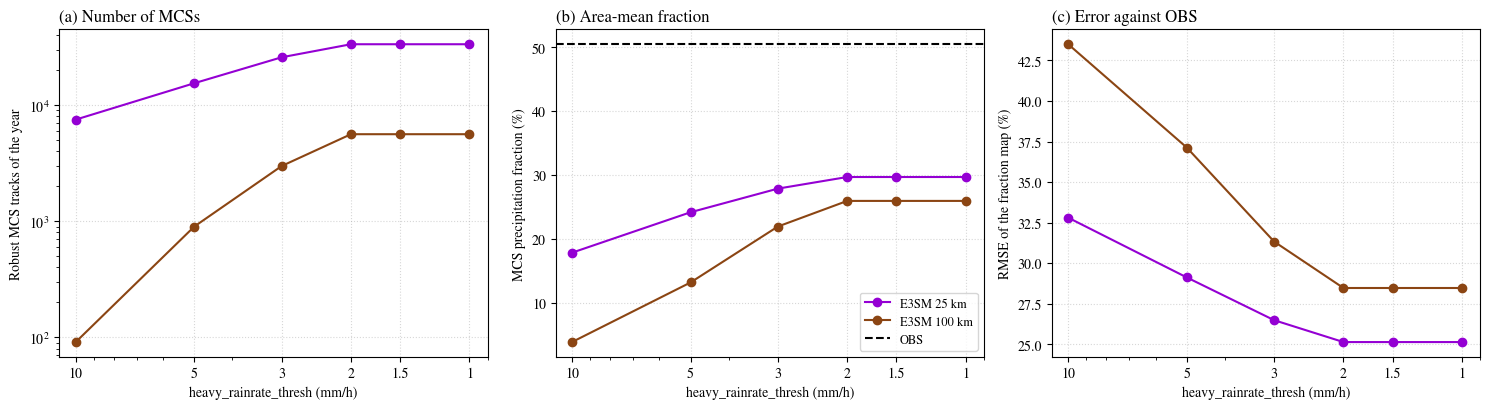

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
frac_title = VARIABLES['pcpfrac']['title']
for ax, column, ylabel, title in ((axes[0], 'robust MCS', 'Robust MCS tracks of the year', '(a) Number of MCSs'),
                                  (axes[1], frac_title, 'MCS precipitation fraction (%)', '(b) Area-mean fraction'),
                                  (axes[2], 'fraction RMSE', 'RMSE of the fraction map (%)', '(c) Error against OBS')):
    # One line per model over the thresholds (the baseline is the largest value)
    for mkey, mcfg in MODELS.items():
        part = summary[summary['model'] == mcfg['label']].sort_values('threshold')
        ax.plot(part['threshold'], part[column], marker='o', color=mcfg['color'], label=mcfg['label'])
    if column == frac_title:
        ax.axhline(summary.loc[summary['model'] == OBS['label'], frac_title].iloc[0], color='k', linestyle='--', label=OBS['label'])
    ax.set_xlabel('heavy_rainrate_thresh (mm/h)')
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc='left')
    ax.set_xscale('log')
    ax.set_xlim(11, 0.9)           # the threshold decreases to the right: the criterion is relaxed
    ax.set_xticks([1, 1.5, 2, 3, 5, 10])
    ax.set_xticklabels(['1', '1.5', '2', '3', '5', '10'])
    ax.grid(True, alpha=0.5, linestyle=':')
    if column == 'robust MCS':
        ax.set_yscale('log')
axes[1].legend(fontsize=9)
fig.tight_layout()
figname = f'{figdir}heavyrain_sensitivity_summary_{season}.png'
fig.savefig(figname, dpi=dpi, bbox_inches='tight', facecolor='w')
print(f'Figure saved: {figname}')
plt.show()

## OBS and bias maps for every threshold, with the zonal mean
One figure per model, variable and season. The key variable, the MCS precipitation fraction, is first.

OBS zonal means per year and cell IQR read from /pscratch/sd/f/feng045/SCREAM-decadal/mcs_global_v3/obs_zonal_annual_2007_2017_ANN.nc


Figure saved: /pscratch/sd/f/feng045/SCREAM-decadal/figures_e3sm/heavyrain_sensitivity/heavyrain_ne120_pcpfrac_obs_and_bias_ANN.png


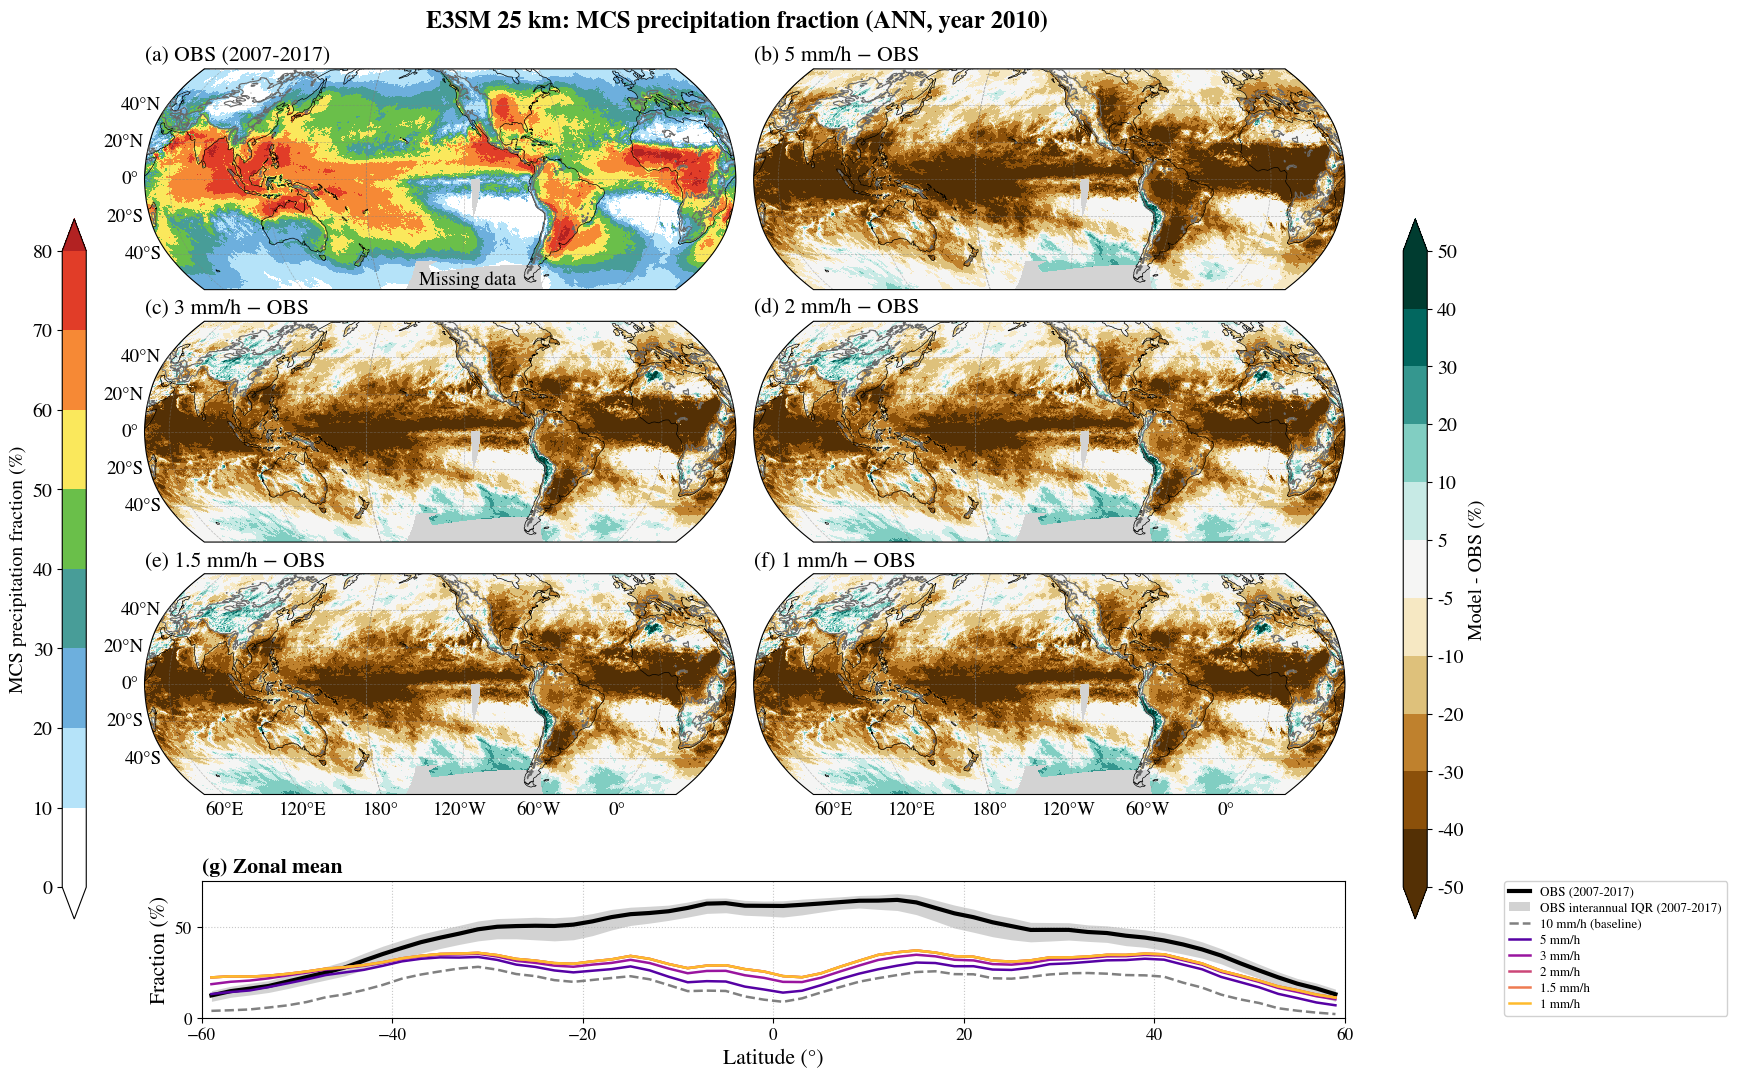

Figure saved: /pscratch/sd/f/feng045/SCREAM-decadal/figures_e3sm/heavyrain_sensitivity/heavyrain_ne120_cloudfreq_obs_and_bias_ANN.png


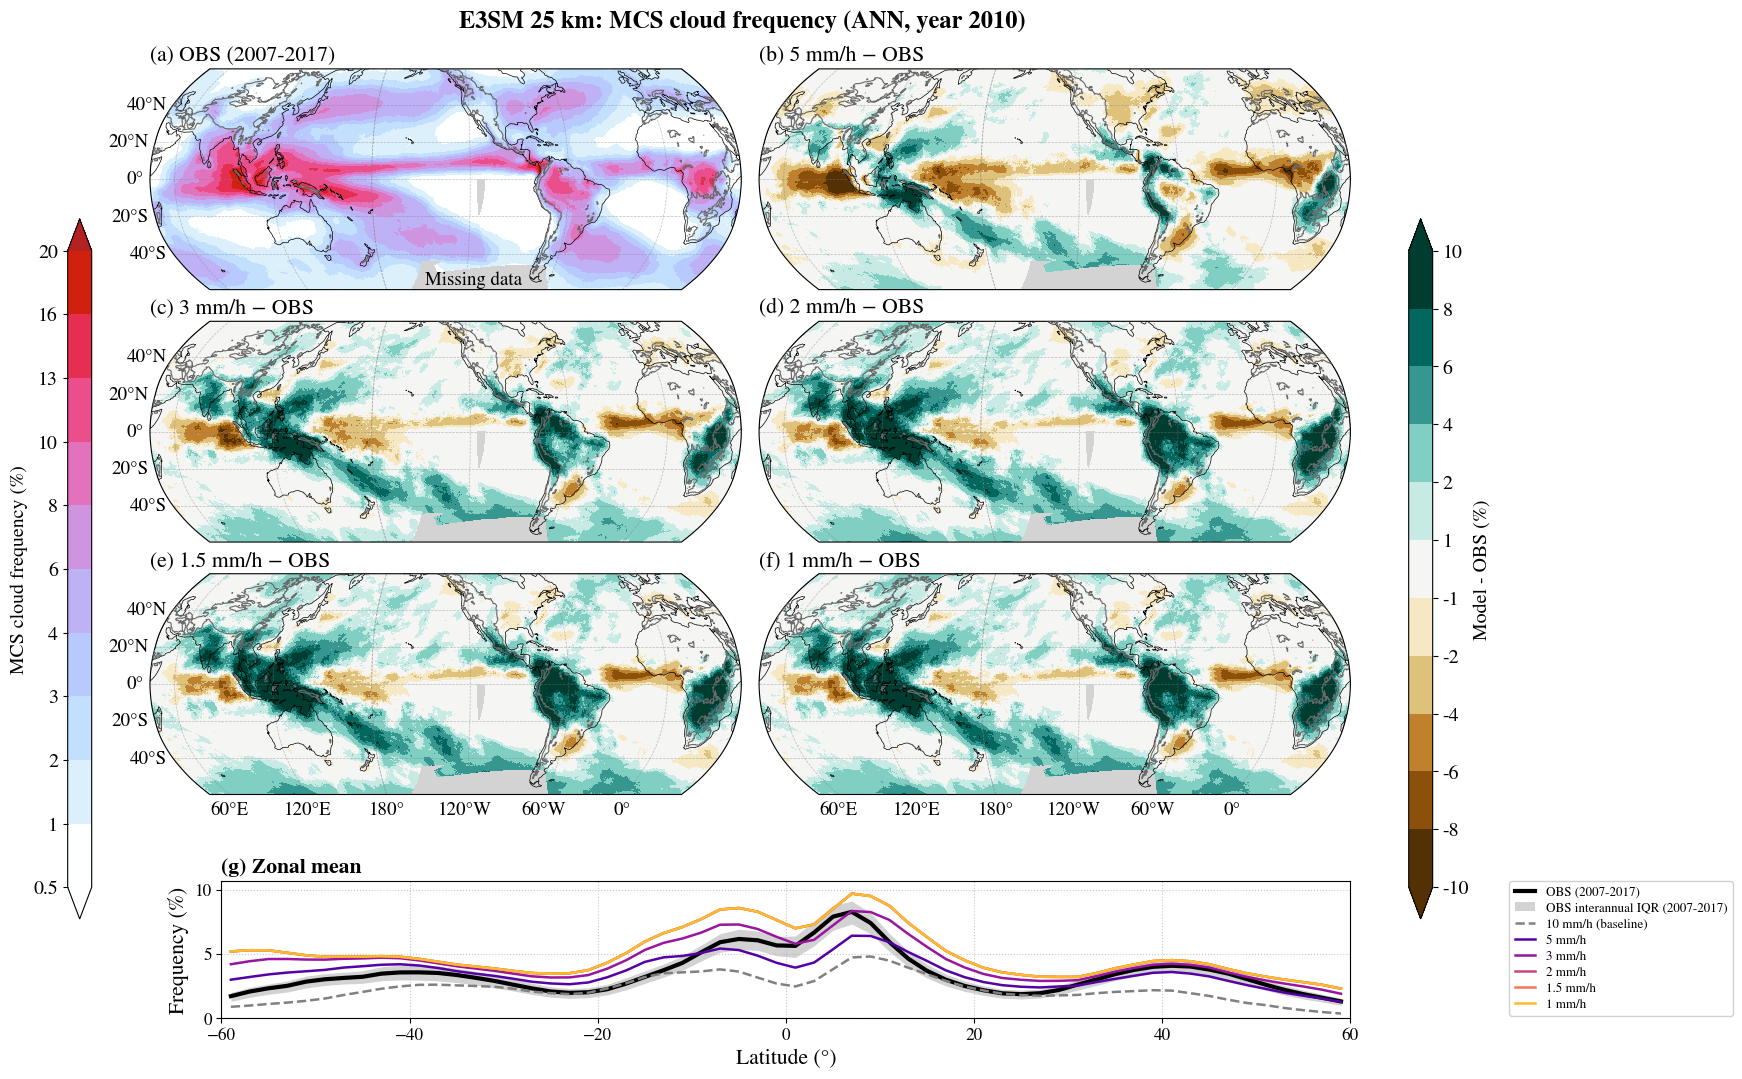

Figure saved: /pscratch/sd/f/feng045/SCREAM-decadal/figures_e3sm/heavyrain_sensitivity/heavyrain_ne120_mcspcp_obs_and_bias_ANN.png


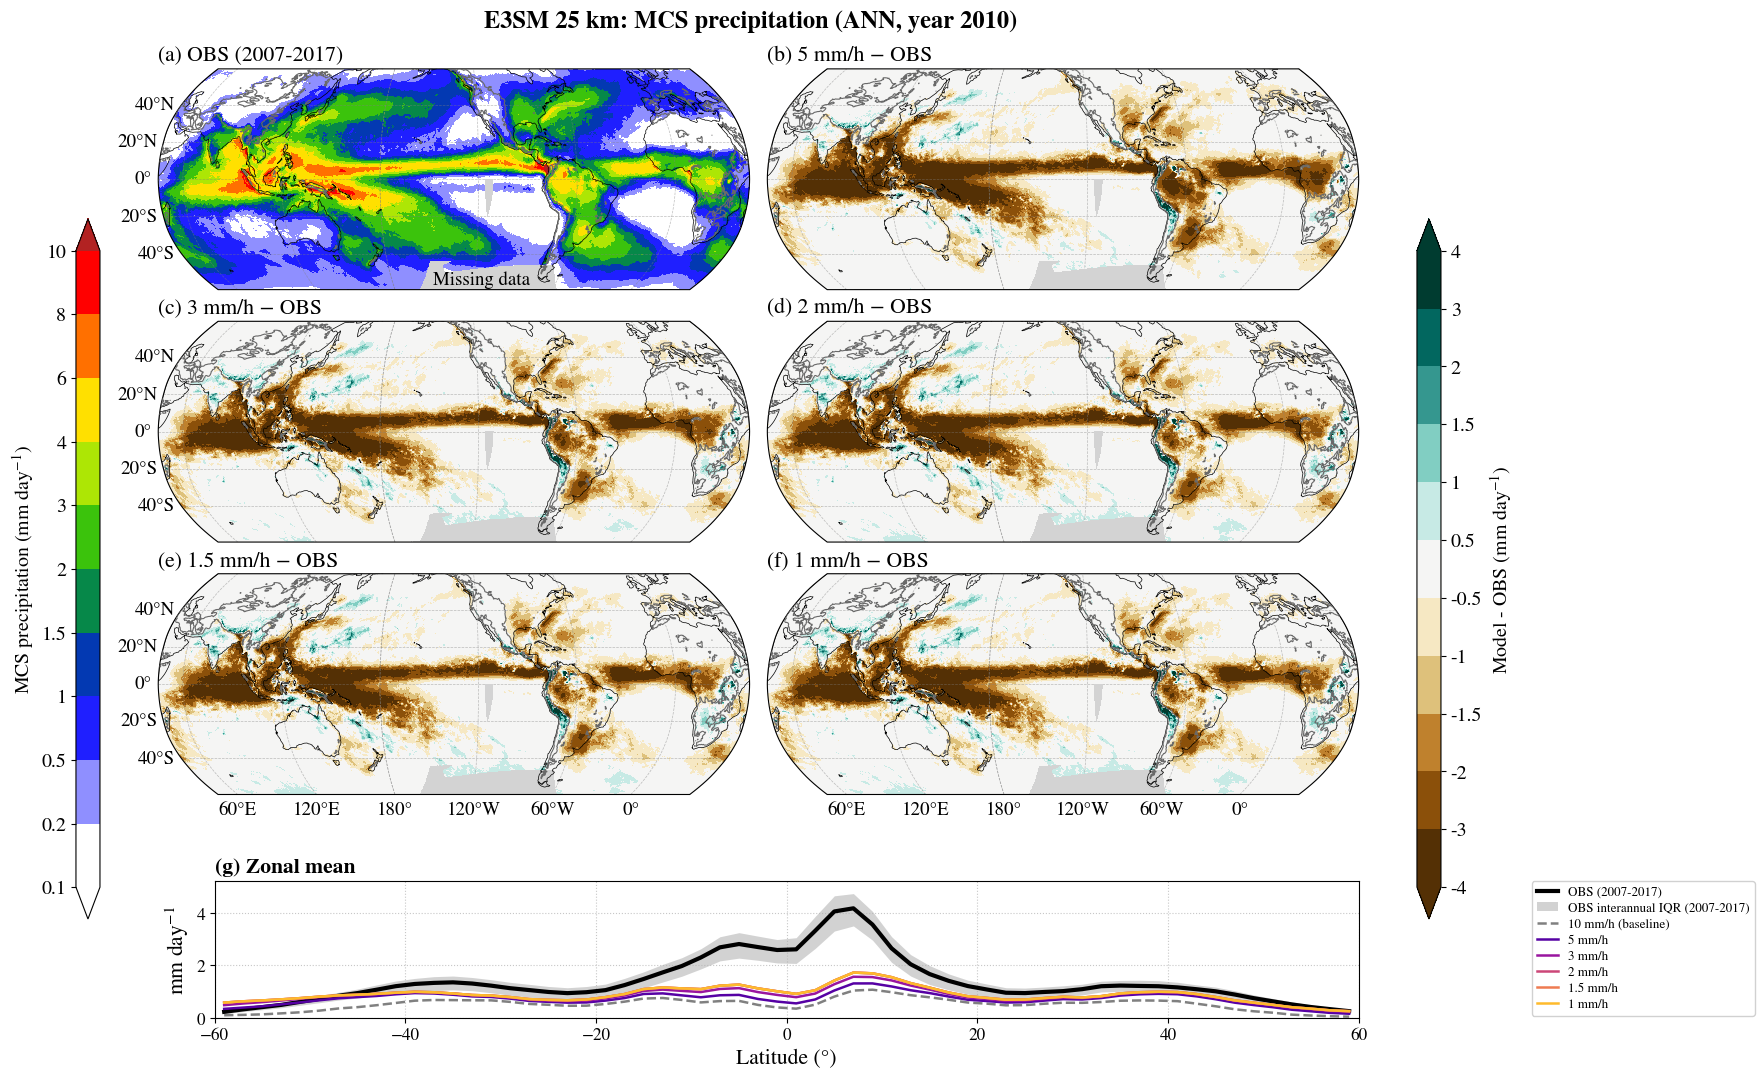

Figure saved: /pscratch/sd/f/feng045/SCREAM-decadal/figures_e3sm/heavyrain_sensitivity/heavyrain_ne30_pcpfrac_obs_and_bias_ANN.png


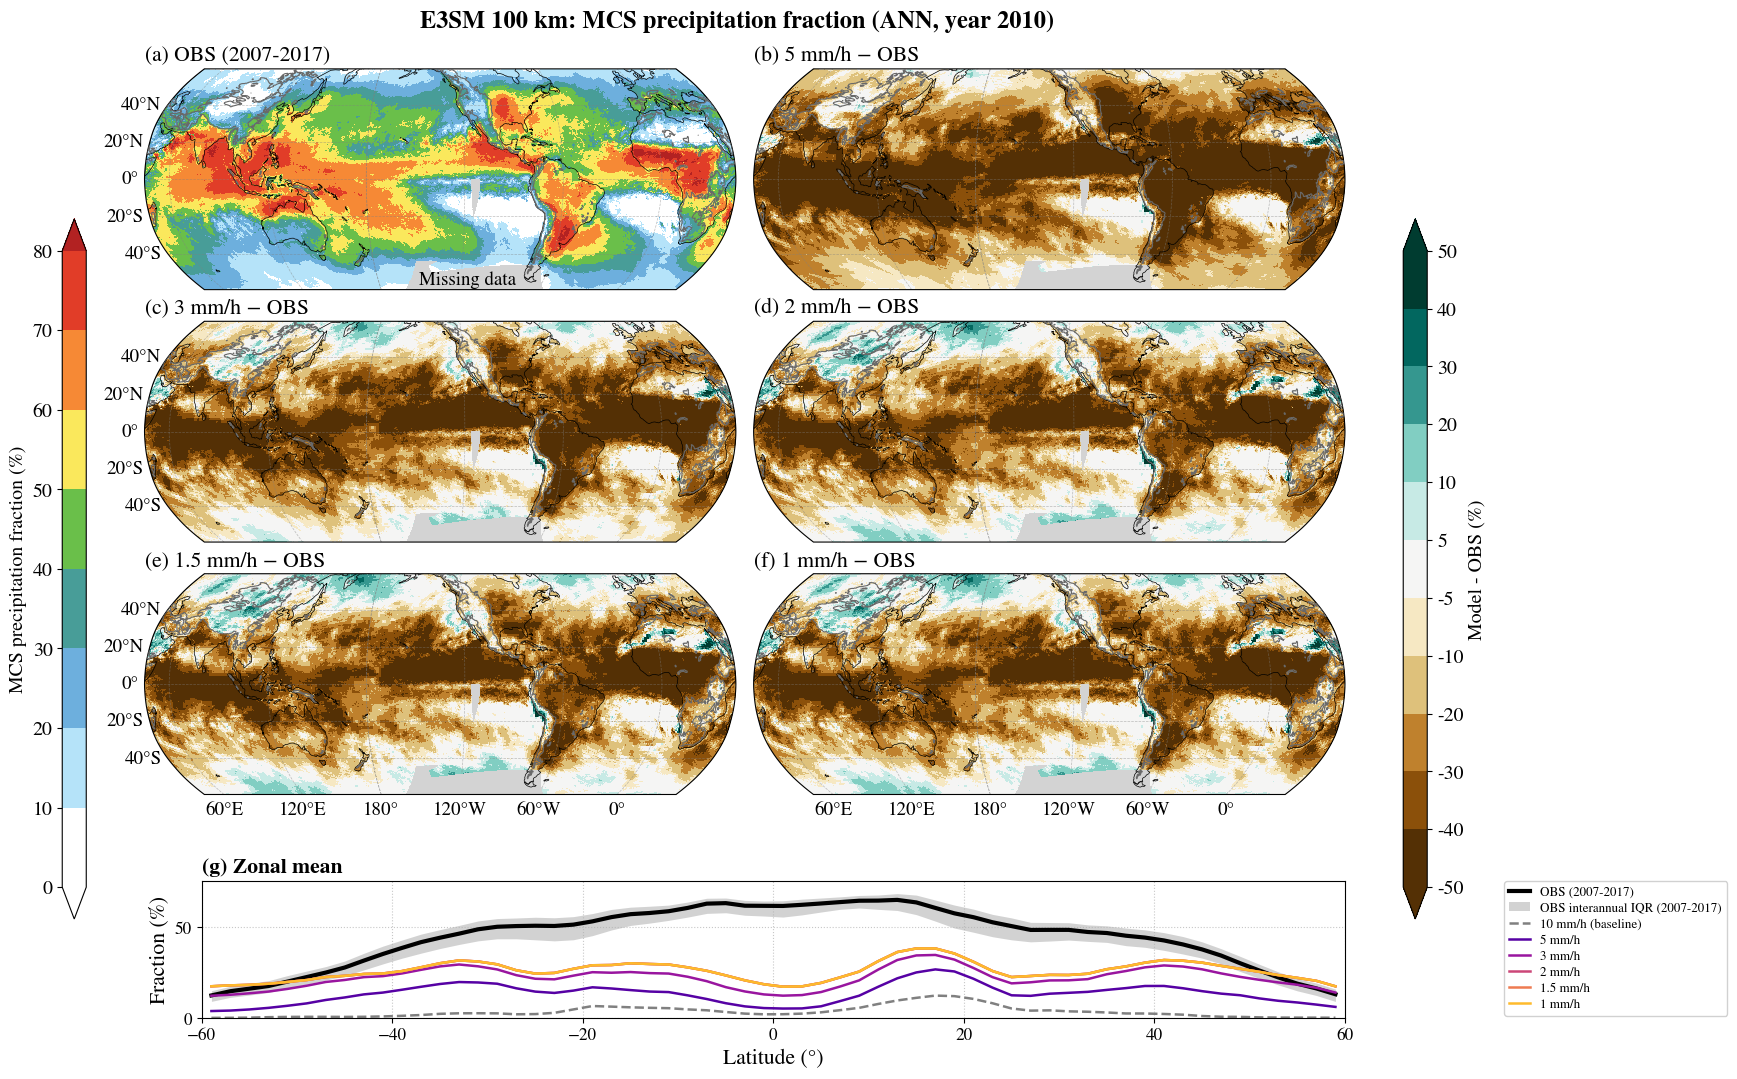

Figure saved: /pscratch/sd/f/feng045/SCREAM-decadal/figures_e3sm/heavyrain_sensitivity/heavyrain_ne30_cloudfreq_obs_and_bias_ANN.png


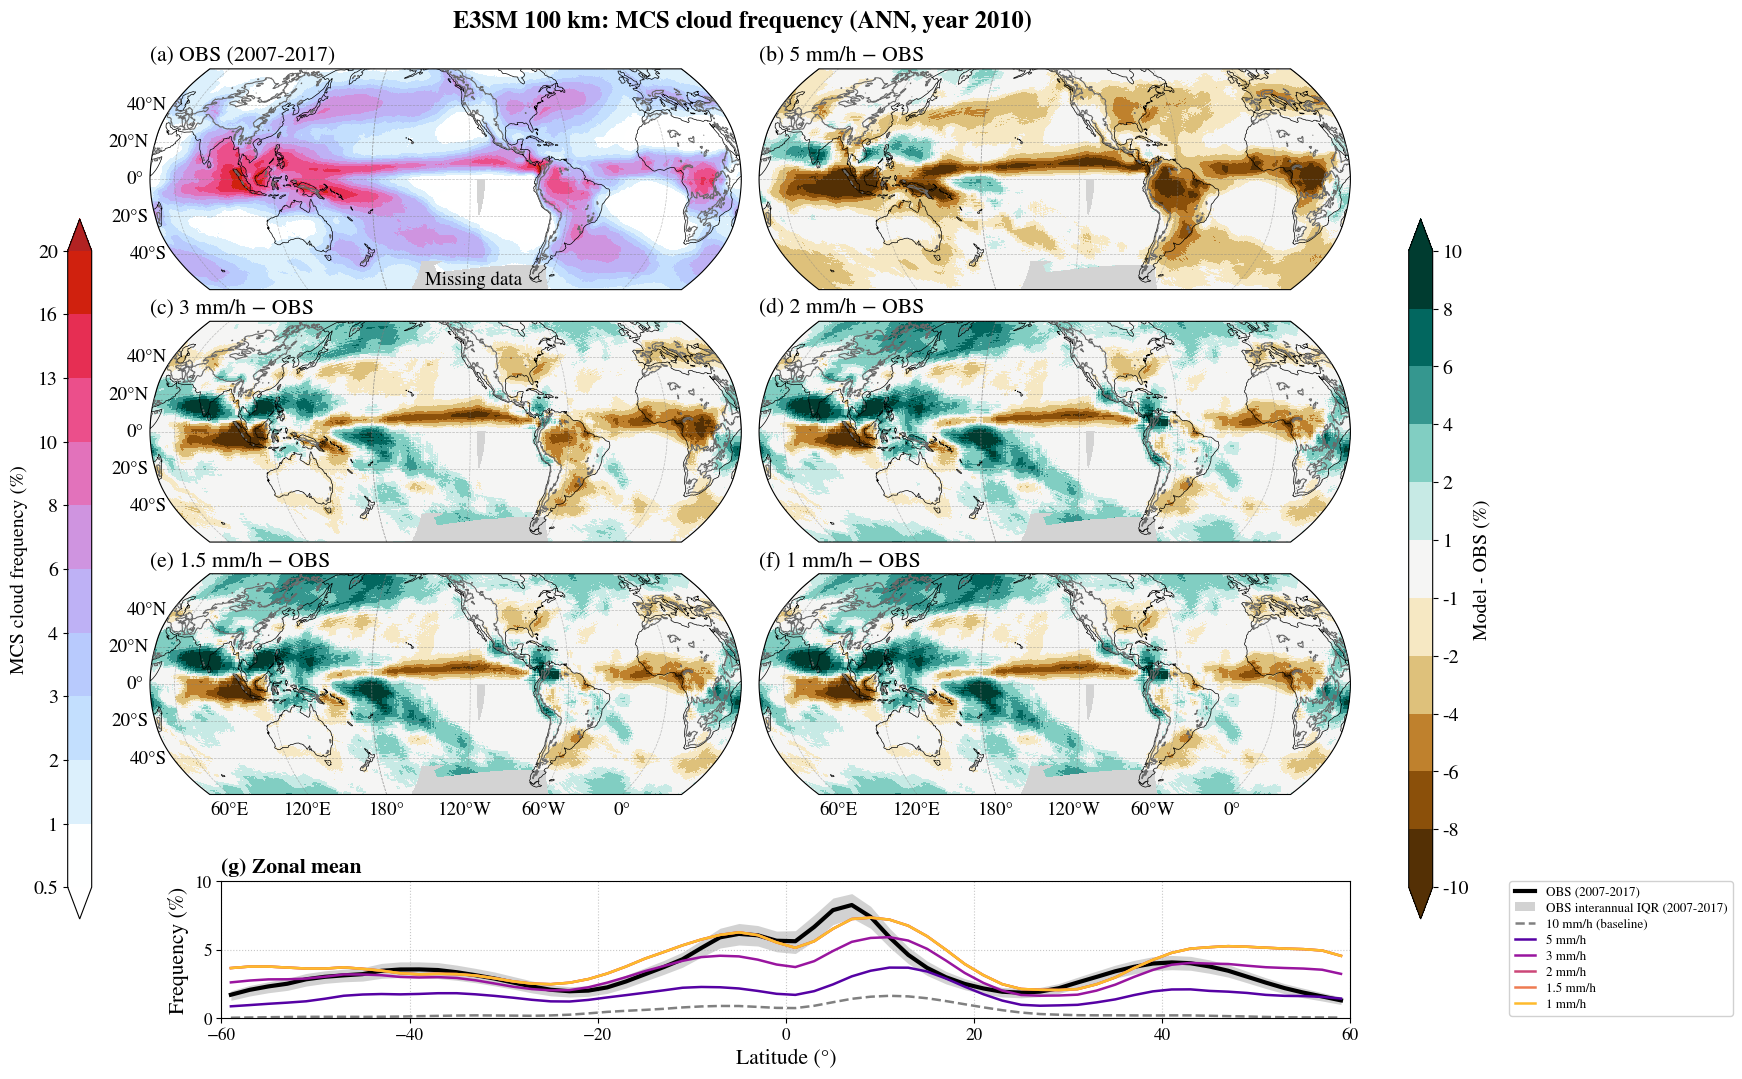

Figure saved: /pscratch/sd/f/feng045/SCREAM-decadal/figures_e3sm/heavyrain_sensitivity/heavyrain_ne30_mcspcp_obs_and_bias_ANN.png


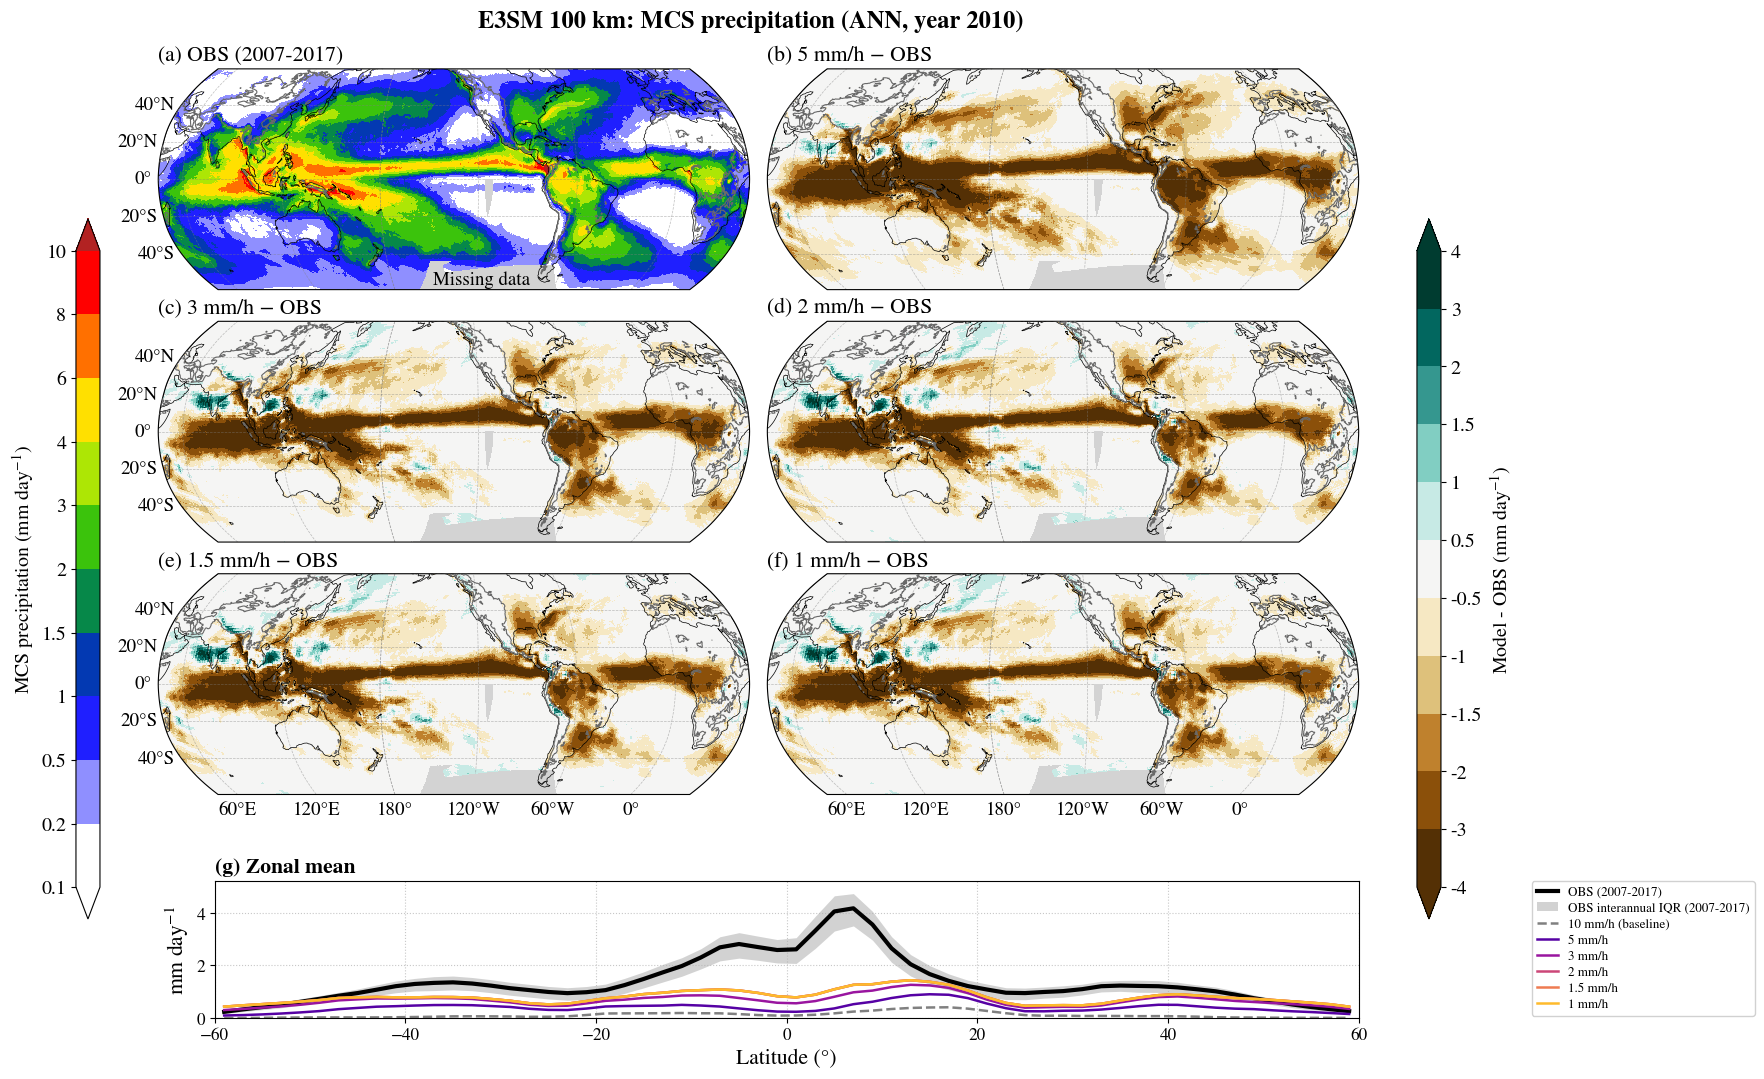

In [10]:
letters = 'abcdefghijklmnopqrstuvwxyz'

for season in SEASONS:
    # Interannual spread of the OBS zonal mean of every variable (made once per season, read from the cache afterwards)
    obs_band = None
    if show_obs_iqr:
        obs_band = obs_zonal_band({v: VARIABLES[v] for v in VARIABLES_TO_PLOT}, valid_for_stats, obs_monthly_dir, obs_iqr_years, obs_lat, obs_lon,
                                  season=season, bin_deg=zonal_bin_deg, lat_cut=lat_cut, max_coord_diff=max_coord_diff,
                                  cache=obs_iqr_cache.replace('.nc', f'_{season}.nc'), method=obs_iqr_method)
    for mkey, mcfg in MODELS.items():
        found = sorted(runs[mkey], reverse=True)
        thresholds = [t for t in found if t != BASELINE_THRESHOLD]
        if not thresholds:
            print(f'{mcfg["label"]}: no sensitivity run found, no maps')
            continue
        # Colors of the thresholds from the colormap (light for the highest, dark for the lowest value)
        colors_thr = {t: mpl.colormaps[threshold_cmap](0.15 + 0.7 * i / max(len(thresholds) - 1, 1)) for i, t in enumerate(thresholds)}
        # One figure per variable
        for vkey in VARIABLES_TO_PLOT:
            spec = VARIABLES[vkey]
            obs_map = obs_fields[season][vkey]['obs']['map']
            maps = thresholds if not (SHOW_BASELINE_MAP and BASELINE_THRESHOLD in found) else [BASELINE_THRESHOLD] + thresholds
            # Model - OBS of every map (cells valid in OBS)
            biases = []
            for t in maps:
                d = fields[season][mkey][vkey][t]['map'] - obs_map
                biases.append(d.where(valid_obs) if mask_to_obs_valid else d)
            # Zonal-mean lines: OBS, the baseline (if found) and every threshold
            lines = []
            centers, values = zonal_mean_cosw(obs_fields[season][vkey]['obs']['num'], obs_fields[season][vkey]['obs']['den'], spec['scale'],
                                              valid_for_stats, zonal_bin_deg, lat_cut)
            obs_line = dict(lat=centers, values=values, label=f"{OBS['label']} ({OBS['period']})", color=OBS['color'],
                            linewidth=OBS['linewidth'], linestyle=OBS['linestyle'])
            if obs_band is not None:
                b = obs_band[vkey]
                assert np.allclose(b['lat'], centers), 'the band and the OBS line must be on the same latitude bins'
                obs_line.update(band=(b['q25'], b['q75']), band_color=obs_iqr_color, band_alpha=obs_iqr_alpha,
                                band_label=f"OBS interannual IQR ({obs_iqr_years[0]}-{obs_iqr_years[1]})")
            lines.append(obs_line)
            for t in ([BASELINE_THRESHOLD] if BASELINE_THRESHOLD in found else []) + thresholds:
                f = fields[season][mkey][vkey][t]
                centers, values = zonal_mean_cosw(f['num'], f['den'], spec['scale'], valid_for_stats, zonal_bin_deg, lat_cut)
                style = baseline_style if t == BASELINE_THRESHOLD else dict(color=colors_thr[t], linewidth=1.8, linestyle='-')
                lines.append(dict(lat=centers, values=values, label=f'{t:g} mm/h' + (' (baseline)' if t == BASELINE_THRESHOLD else ''), **style))
            # Titles: observation, then one bias per map, then the zonal mean
            titles = [f"({letters[0]}) {OBS['label']} ({OBS['period']})"]
            titles += [f"({letters[i + 1]}) {t:g} mm/h − OBS" for i, t in enumerate(maps)]
            fig = plot_obs_and_bias_maps(
                obs_map.where(valid_obs) if mask_to_obs_valid else obs_map, biases, titles, spec['levels'], spec['bias_levels'],
                get_cmap(spec['cmap'], over=spec['obs_over'], under=spec['obs_under']), get_cmap(spec['bias_cmap']),
                spec['cblabel'], spec['bias_cblabel'], zonal_lines=lines,
                zonal_title=f'({letters[len(maps) + 1]}) Zonal mean', zonal_ylabel=spec['zonal_ylabel'], ncol=ncol, missing=missing,
                terrain=terrain, terrain_levels=terrain_levels, lat_lines=lat_lines, central_lon=central_lon, lat_range=lat_range,
                lat_cut=lat_cut, figwidth=figwidth, figsize=figsize, panel_aspect=panel_aspect, aspect=aspect,
                zonal_legend_ncol=zonal_legend_ncol, zonal_legend_outside=zonal_legend_outside, zonal_headroom=zonal_headroom,
                fontsize=fontsize, cb_fontsize=cb_fontsize, plot_coarsen=plot_coarsen,
                figtitle=f"{mcfg['label']}: {spec['title']} ({season}, year {YEAR})",
                figname=f"{figdir}heavyrain_{mkey}_{vkey}_obs_and_bias_{season}.png", dpi=dpi)
            plt.show()